# Training ME5S for Binary Safety Classification

In [58]:
from __future__ import annotations

import json
import math
import os
import random
import shutil
from collections import OrderedDict
from enum import StrEnum
from pathlib import Path
from typing import Any, Literal

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

# In-notebook rendering of the per-epoch attention heatmaps.
from IPython.display import HTML, display

from datasets import Dataset as HFDataset
from datasets import DatasetDict
from datasets import load_dataset
from peft import LoraConfig, TaskType, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict
from peft.utils import load_peft_weights
from torch import Tensor
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup

# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------

# ME5-small: 12-layer BERT encoder, hidden_dim=384, distilled from XLM-R
MODEL_ID = "intfloat/multilingual-e5-small"
HIDDEN_DIM = 384
MAX_LEN = 128

# Safety dataset
DATASET_ID = "nvidia/Aegis-AI-Content-Safety-Dataset-2.0"

# Records kept from each cleaned split (see clean_aegis_splits); None keeps all of
# them, so the binary and multi-label classifiers train and test on identical splits.
SUBSET_SIZE: int | None = None
VAL_SIZE: int | None = None
TEST_SIZE: int | None = None

BATCH_SIZE = 64

GRAD_CLIP_NORM = 1.0

WARMUP_RATIO = 0.05

NUM_EPOCHS = 100
LOG_EVERY = 25

VISUALIZE_EVERY = 10

# Fixed records tracked by the per-epoch diagnostics: half from train, half
# from validation, each half split evenly between safe and unsafe prompts.
NUM_REPRESENTATIVE = 12

# Decision threshold on p(unsafe | theta) for the accuracy/precision/recall metrics.
UNSAFE_THRESHOLD = 0.5

# LoRA adapters on the attention projections of every encoder layer. PEFT matches
# target entries by module-name suffix, so "attention.output.dense" targets only
# the attention O-projection and never the FFN's separate "output.dense" module.
LORA_RANK = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.05
LORA_TARGET_MODULES = ["query", "key", "value", "attention.output.dense"]

# Feed-forward classification head.
HEAD_NUM_LAYERS = 5
HEAD_HIDDEN_DIM = 512
HEAD_WEIGHT_INIT = "x_normal"

# Checkpointing: the resumable training state is written every CHECKPOINT_EVERY
# epochs (and after the final epoch), overwriting the previous one. The model with
# the lowest validation loss is exported to RUN_DIR / "best" whenever it improves.
OUTPUT_DIR = Path("../outputs/binary_classifier")
RUN_NAME = "me5s_lora_binary"
RESUME = False
CHECKPOINT_EVERY = 10

SEED = 0


def seed_everything(seed: int) -> None:
    """
    Seed the Python, NumPy, and PyTorch (CPU and CUDA) random number generators.

    :param seed:    Seed shared by every generator.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything(SEED)

In [59]:
class AegisLabels(StrEnum):
    SAFE = "safe"
    UNSAFE = "unsafe"


class AegisKeys(StrEnum):
    PROMPT = "prompt"
    RESPONSE = "response"
    PROMPT_LABEL = "prompt_label"
    RESPONSE_LABEL = "response_label"
    VIOLATED_CATEGORIES = "violated_categories"
    PROMPT_LABEL_SOURCE = "prompt_label_source"

In [60]:
def average_pool(last_hidden_states: Tensor, non_padding_mask: Tensor) -> Tensor:
    """
    Mean-pool token hidden states over non-padded positions.

    :param last_hidden_states:  Shape ``(B, L, D)`` — one vector per token position.
    :param non_padding_mask:    Shape ``(B, L)`` — 1 for real tokens, 0 for padding.
    :return:                    Shape ``(B, D)`` — one dense embedding per input sequence.
    """
    # [B, L, D] — zero out padded positions so they do not contribute to the sum.
    b, l, d = last_hidden_states.shape
    last_hidden = last_hidden_states.masked_fill(~non_padding_mask.reshape(b, l, 1).bool(), 0.0)

    # [B, D] — divide the summed vectors by the count of real tokens per sequence.
    return last_hidden.sum(dim=1) / non_padding_mask.sum(dim=1).reshape(b, 1)

In [61]:
def make_collate_fn(
    tokenizer: Any,
    max_length: int = 512,
):
    """
    Return a DataLoader collate function that tokenizes raw Aegis prompts.

    Tokenization happens at collation time so that each batch is padded to its
    own maximum length rather than the global maximum.

    :param tokenizer:   A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:  Maximum token length for truncation.
    :return:            A collate callable for :class:`DataLoader`.
    """

    def _collate(
        batch: list[dict[str, Any]],
    ) -> tuple[dict[str, Tensor], Tensor]:
        texts = [row[AegisKeys.PROMPT] for row in batch]

        # "unsafe" is the positive class: 1.0 for unsafe prompts, 0.0 for safe.
        unsafe_star = torch.tensor(
            [float(row[AegisKeys.PROMPT_LABEL] == AegisLabels.UNSAFE) for row in batch],
            dtype=torch.float32,
        )

        # Tokenize the batch of raw prompts in one call.
        batch_dict: dict[str, Tensor] = tokenizer(
            texts,
            max_length=max_length,
            padding=True,
            truncation=True,
            return_tensors="pt",
        )

        return batch_dict, unsafe_star

    return _collate

In [62]:
# Aegis stores prompts that could not be released verbatim as this placeholder.
REDACTED_PROMPT = "REDACTED"

# Official splits in leakage-removal order: a prompt that occurs in several splits
# is kept only in the last of them, so no evaluation prompt is seen in training.
AEGIS_SPLITS = ("train", "validation", "test")


def parse_categories(raw: str | None) -> list[str]:
    """
    Split an Aegis ``violated_categories`` string into category names.

    :param raw: Comma-separated categories; ``None`` or empty means none.
    :return:    Stripped category names in their original order.
    """
    return [category.strip() for category in (raw or "").split(",") if category.strip()]


def clean_aegis_splits(
    dataset_dict: DatasetDict,
    tokenizer: Any,
    max_length: int,
) -> dict[str, HFDataset]:
    """
    Build deduplicated, leakage-free prompt splits that fit the token budget.

    Aegis pairs one prompt with several responses, so a prompt can repeat within a
    split and across splits. Each split is cleaned in five steps:

    1. Drop ``REDACTED`` placeholder prompts, whose text cannot support any label.
    2. Drop prompts longer than ``max_length`` tokens (special tokens included), so
       the collate function never truncates.
    3. Merge repeated prompts into one record whose categories are the union over
       the repeats in first-seen order; ``violated_categories`` is already a union
       over annotators, so the union keeps its meaning.
    4. Drop prompts whose repeats disagree on ``prompt_label``.
    5. Drop prompts that also occur in a later split (train, validation, test).

    :param dataset_dict:    The Aegis splits ``train``, ``validation``, and ``test``.
    :param tokenizer:       A HuggingFace ``PreTrainedTokenizer``.
    :param max_length:      Maximum allowed token length (inclusive).
    :return:                Split name to a dataset with ``prompt``, ``prompt_label``,
                            and ``violated_categories`` columns, in first-seen order.
    """
    prompt_key = AegisKeys.PROMPT.value
    label_key = AegisKeys.PROMPT_LABEL.value
    categories_key = AegisKeys.VIOLATED_CATEGORIES.value

    # Steps 1-3: group each split's in-budget, non-redacted records by exact prompt,
    # collecting every label seen and the union of categories.
    grouped: dict[str, dict[str, tuple[set[str], list[str]]]] = {}
    raw_sizes: dict[str, int] = {}
    for split in AEGIS_SPLITS:
        dataset = dataset_dict[split]
        prompts = list(dataset[prompt_key])
        labels = list(dataset[label_key])
        raw_categories = list(dataset[categories_key])
        input_ids = tokenizer(prompts, truncation=False, verbose=False)["input_ids"]
        raw_sizes[split] = len(prompts)

        groups: dict[str, tuple[set[str], list[str]]] = {}
        for prompt, label, raw, ids in zip(prompts, labels, raw_categories, input_ids, strict=True):
            if len(ids) > max_length or prompt.strip().upper() == REDACTED_PROMPT:
                continue
            seen_labels, merged = groups.setdefault(prompt, (set(), []))
            seen_labels.add(label)
            for category in parse_categories(raw):
                if category not in merged:
                    merged.append(category)
        grouped[split] = groups

    # Steps 4-5: drop label conflicts and prompts that reappear in a later split.
    cleaned: dict[str, HFDataset] = {}
    print(f"{'split':<12}{'records':>9}{'unique fit':>12}{'conflicts':>11}{'leaked':>8}{'kept':>8}")
    for position, split in enumerate(AEGIS_SPLITS):
        later_prompts: set[str] = set().union(*(grouped[s] for s in AEGIS_SPLITS[position + 1:]))
        records: dict[str, list[str]] = {prompt_key: [], label_key: [], categories_key: []}
        num_conflicts = 0
        num_leaked = 0
        for prompt, (seen_labels, merged) in grouped[split].items():
            if len(seen_labels) > 1:
                num_conflicts += 1
                continue
            if prompt in later_prompts:
                num_leaked += 1
                continue
            records[prompt_key].append(prompt)
            records[label_key].append(next(iter(seen_labels)))
            records[categories_key].append(", ".join(merged))
        cleaned[split] = HFDataset.from_dict(records)
        print(
            f"{split:<12}{raw_sizes[split]:>9}{len(grouped[split]):>12}{num_conflicts:>11}"
            f"{num_leaked:>8}{len(cleaned[split]):>8}"
        )
    return cleaned


def take_leading(dataset: HFDataset, size: int | None) -> HFDataset:
    """
    Keep the first ``size`` records of a cleaned split, or all of them for ``None``.

    :param dataset: A split returned by :func:`clean_aegis_splits`.
    :param size:    Number of records to keep; ``None`` keeps every record.
    :return:        The leading records, in their original order.
    """
    if size is None:
        return dataset
    if size > len(dataset):
        print(f"Warning: only {len(dataset)} cleaned records available; requested {size}.")
    return dataset.select(range(min(size, len(dataset))))

In [63]:
# ---------------------------------------------------------------------------
# Load the ME5-small backbone and wrap it with LoRA adapters.
# ---------------------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load with the eager attention implementation so `output_attentions=True`
# actually returns per-layer attention weights. The default SDPA kernel fuses
# the softmax and silently yields no attention maps, which the heatmaps need.
base_model = AutoModel.from_pretrained(MODEL_ID, attn_implementation="eager")

# LoRA targets the Q, K, V attention projections in every encoder layer.
# The leaf module names inside BertSelfAttention are "query", "key", "value",
# which are collision-free (the FFN projections are named "dense").
lora_config = LoraConfig(
    task_type=TaskType.FEATURE_EXTRACTION,
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=LORA_TARGET_MODULES,
    # QKV-only fallback (the original, lower-capacity configuration):
    # target_modules=["query", "key", "value"],
)

lora_model = get_peft_model(base_model, lora_config)
lora_model.print_trainable_parameters()

# ---------------------------------------------------------------------------
# Instantiate the dataset and dataloader.
# ---------------------------------------------------------------------------

# Deduplicated, leakage-free prompts that fit within MAX_LEN tokens, so no record
# is truncated by the collate function (see clean_aegis_splits).
collate_fn = make_collate_fn(tokenizer, max_length=MAX_LEN)

aegis_dataset = load_dataset(DATASET_ID)
cleaned_splits = clean_aegis_splits(aegis_dataset, tokenizer, MAX_LEN)
train_dataset = take_leading(cleaned_splits["train"], SUBSET_SIZE)
val_dataset = take_leading(cleaned_splits["validation"], VAL_SIZE)
test_dataset = take_leading(cleaned_splits["test"], TEST_SIZE)

# A dedicated generator makes the shuffling order reproducible and resumable.
train_generator = torch.Generator().manual_seed(SEED)

# pin_memory + worker processes keep the batches flowing to the GPU.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    collate_fn=collate_fn,
    pin_memory=True,
    num_workers=2,
)

# Validation is evaluation-only: no shuffling (deterministic ordering) and no
# worker processes, since it runs a single quick no-grad pass per epoch.
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    pin_memory=True,
)

# The test set is evaluated once, after training, with the same settings.
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    pin_memory=True,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

trainable params: 589,824 || all params: 118,243,584 || trainable%: 0.4988
split         records  unique fit  conflicts  leaked    kept
train           30007       19524        165     309   19050
validation       1445        1025          0       9    1016
test             1964        1711          1       0    1710


In [64]:
def label_counts(dataset: HFDataset) -> tuple[int, int]:
    """
    Count the safe and unsafe prompts in an Aegis split.

    :param dataset: An Aegis split (or subset of one).
    :return:        ``(num_safe, num_unsafe)``.
    """
    labels = list(dataset[AegisKeys.PROMPT_LABEL])
    return labels.count(AegisLabels.SAFE), labels.count(AegisLabels.UNSAFE)


print(f"{'split':<12}{'size':>8}{'safe':>8}{'unsafe':>8}{'% unsafe':>10}")
for split_name, ds in [("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)]:
    num_safe, num_unsafe = label_counts(ds)
    print(
        f"{split_name:<12}{len(ds):>8}{num_safe:>8}{num_unsafe:>8}"
        f"{100 * num_unsafe / len(ds):>9.1f}%"
    )

split           size    safe  unsafe  % unsafe
train          19050    8882   10168     53.4%
validation      1016     433     583     57.4%
test            1710     759     951     55.6%


In [65]:
class BinaryFFN(nn.Module):
    """
    Feed-forward head that maps a pooled embedding to a safety classification.

    :param num_layers:      Total number of linear layers (must be >= 2).
    :param input_dim:       Dimensionality of the pooled embedding input.
    :param hidden_dim:      Width of the hidden layers.
    :param weight_init:     Initialization strategy for hidden layers.
    """

    # Number of raw scalar outputs.
    NUM_RAW_OUTPUTS: int = 1

    def __init__(
        self,
        num_layers: int,
        input_dim: int,
        hidden_dim: int,
        weight_init: Literal["x_uniform", "x_normal", "zeros"] = "x_uniform",
    ) -> None:
        super().__init__()
        assert num_layers >= 2, "Need at least an input layer and an output layer."
        assert hidden_dim > 0

        # Select the weight initialization function for hidden layers.
        match weight_init:
            case "x_uniform":
                weight_init_fn = nn.init.xavier_uniform_
            case "x_normal":
                weight_init_fn = nn.init.xavier_normal_
            case "zeros":
                weight_init_fn = nn.init.zeros_
            case _:
                raise ValueError(f"Unknown weight_init: {weight_init!r}")

        # Construct the layer stack: Linear -> [GELU -> Linear] x (num_layers - 1).
        layers: list[tuple[str, nn.Module]] = [("00_Linear", nn.Linear(input_dim, hidden_dim))]
        for i in range(1, num_layers):
            if i < num_layers - 1:
                # Hidden layer: user-selected initialization.
                linear = nn.Linear(hidden_dim, hidden_dim)
                # weight_init_fn(linear.weight)
            else:
                # Output layer: zero-initialized weights for a neutral start.
                linear = nn.Linear(hidden_dim, self.NUM_RAW_OUTPUTS)
                # nn.init.zeros_(linear.weight)
            weight_init_fn(linear.weight)

            nn.init.zeros_(linear.bias)
            layers.extend(
                [
                    (f"{i:02d}_GELU", nn.GELU()),
                    (f"{i:02d}_Linear", linear),
                ]
            )

        self.model = nn.Sequential(OrderedDict(layers))

    def forward(self, x: Tensor) -> Tensor:
        """
        Map a pooled embedding to an unsafe-class logit.

        :param x:   Pooled embedding of shape ``(B, input_dim)``.
        :return:    Logits of shape ``(B,)``.
        """
        # [B, input_dim] -> [B, 1]
        raw = self.model(x)
        # [B, 1] -> [B,]
        return raw.squeeze(1)


class SafetyModel(nn.Module):
    """
    End-to-end safety task-head: LoRA-adapted ME5-small encoder followed
    by a mean-pool and a feed-forward binary classification head.

    :param embedding_model:     A PEFT-wrapped HuggingFace encoder.
    :param ffn_model:           The :class:`BinaryFFN` head.

    """

    def __init__(
        self,
        embedding_model: nn.Module,
        ffn_model: BinaryFFN,
    ) -> None:
        super().__init__()
        self._embedding_model = embedding_model
        self._ffn_model = ffn_model


    def forward(
        self,
        batch_dict: dict[str, Tensor],
        return_attentions: bool = False,
    ) -> Tensor | tuple[Tensor, Tensor, Tensor]:
        """
        Encode the tokenized input and predict if the query is safe or not.

        :param batch_dict:          Tokenizer output dict with ``input_ids`` and
                                    ``attention_mask`` keys.
        :param return_attentions:   When True, also return the final encoder
                                    layer's attention tensor and the attention
                                    mask for heatmap visualization.
        :return:                    Unsafe-class logits of shape ``(B,)``; or,
                                    when ``return_attentions`` is set,
                                    ``(logits, last_layer_attn, attention_mask)``
                                    where ``last_layer_attn`` has shape
                                    ``[B, H, L, L]``.
        """
        # Request per-layer attention weights only when a heatmap is needed;
        # the extra tensors are avoided on the hot training path.
        encoder_kwargs = {"output_attentions": True} if return_attentions else {}

        # Run the LoRA-adapted encoder.
        # [B, L, 384] — one hidden vector per token position.
        emb_outputs = self._embedding_model(**batch_dict, **encoder_kwargs)

        # [B, 384] — mean-pool over non-padded tokens.
        emb_x = average_pool(emb_outputs.last_hidden_state, batch_dict["attention_mask"])

        # [B, 384] -> [B,]
        logits = self._ffn_model(emb_x)

        if not return_attentions:
            return logits

        # emb_outputs.attentions is a tuple of [B, H, L, L] tensors, one per
        # encoder layer. The final layer's map is aggregated downstream into
        # per-token salience for the attention heatmap.
        last_layer_attn = emb_outputs.attentions[-1]
        return logits, last_layer_attn, batch_dict["attention_mask"]

In [66]:
def get_loss_fn(num_positive: int, total: int, device: str):
    num_negative = total - num_positive
    class_weight = torch.tensor([num_negative / num_positive], dtype=torch.float32).to(device)

    return nn.BCEWithLogitsLoss(pos_weight=class_weight)

In [67]:
# ---------------------------------------------------------------------------
# Instantiate the FFN head, the composite model, and the optimizer.
# ---------------------------------------------------------------------------

ffn = BinaryFFN(
    num_layers=HEAD_NUM_LAYERS,
    input_dim=HIDDEN_DIM,
    hidden_dim=HEAD_HIDDEN_DIM,
    weight_init=HEAD_WEIGHT_INIT,
)
safety_model = SafetyModel(lora_model, ffn)

# Muon only supports 2-D parameters. LoRA matrices and FFN weights use
# Muon; biases and any other 1-D trainable parameters use AdamW.
lora_trainable_parameters = [
    parameter for parameter in lora_model.parameters() if parameter.requires_grad
]
ffn_trainable_parameters = [parameter for parameter in ffn.parameters() if parameter.requires_grad]
muon_lora_parameters = [parameter for parameter in lora_trainable_parameters if parameter.ndim == 2]
muon_ffn_parameters = [parameter for parameter in ffn_trainable_parameters if parameter.ndim == 2]
non_muon_parameters = [
    parameter
    for parameter in [*lora_trainable_parameters, *ffn_trainable_parameters]
    if parameter.ndim != 2
]

# torch.optim.Muon was introduced in PyTorch 2.9.0. environment.yaml pins
# torch>=2.9 (installed here as 2.9.1+cu126), so Muon is available and is the
# active path below. The runtime probe is retained purely for portability:
# should the notebook ever run against an older wheel that predates Muon, it
# degrades to a single AdamW rather than raising an AttributeError.
if hasattr(torch.optim, "Muon"):
    # Keep the conservative LoRA rate and the faster FFN rate while satisfying
    # Muon's requirement that every parameter in its groups is two-dimensional.
    optimizer_muon = torch.optim.Muon(
        [
            {"params": muon_lora_parameters, "lr": 1e-4},
            {"params": muon_ffn_parameters, "lr": 1e-3},
        ],
    )
    optimizer_non_muon = torch.optim.AdamW(
        non_muon_parameters,
        lr=1e-3,
        weight_decay=0.01,
    )
    optimizers = [optimizer_muon, optimizer_non_muon]
else:
    # AdamW accepts parameters of any rank, so the 2-D/1-D split is unnecessary.
    # The conservative LoRA rate and the faster FFN rate are preserved through
    # per-group learning rates rather than through two separate optimizers.
    optimizer_adamw = torch.optim.AdamW(
        [
            {"params": lora_trainable_parameters, "lr": 2e-5},
            {"params": ffn_trainable_parameters, "lr": 1e-3},
        ],
        weight_decay=0.01,
    )
    optimizers = [optimizer_adamw]

selected_optimizer = "Muon + AdamW split" if hasattr(torch.optim, "Muon") else "AdamW only"

print(
    f"Optimizer parameters: {len(muon_lora_parameters)} LoRA 2-D, "
    f"{len(muon_ffn_parameters)} FFN 2-D, "
    f"{len(non_muon_parameters)} 1-D; using {selected_optimizer}"
)

# ---------------------------------------------------------------------------
# Learning-rate schedule: linear warmup followed by cosine decay.
# ---------------------------------------------------------------------------

# One scheduler per optimizer so the Muon and AdamW groups share the same
# warmup/decay shape. Warmup eases the early volatility while cosine decay lets
# the run settle instead of bouncing around the plateau at a fixed rate.
steps_per_epoch = len(train_loader)
total_training_steps = NUM_EPOCHS * steps_per_epoch
warmup_steps = int(WARMUP_RATIO * total_training_steps)

schedulers = [
    get_cosine_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_training_steps,
    )
    for optimizer in optimizers
]

print(
    f"Scheduler: {warmup_steps} warmup / {total_training_steps} total steps "
    f"across {len(schedulers)} scheduler(s), cosine decay"
)

Optimizer parameters: 96 LoRA 2-D, 5 FFN 2-D, 5 1-D; using Muon + AdamW split
Scheduler: 1490 warmup / 29800 total steps across 2 scheduler(s), cosine decay


In [68]:
# ---------------------------------------------------------------------------
# Attention heatmap helpers.
#
# The final encoder layer's attention is aggregated into a per-token salience
# score and rendered as background-shaded text spans. These helpers feed
# the periodic in-notebook heatmaps.
# ---------------------------------------------------------------------------


def aggregate_attention(attn: Tensor, attention_mask: Tensor) -> Tensor:
    """
    Reduce a final-layer attention tensor to per-token salience scores.

    Heads are averaged, then each key token's salience is the mean attention it
    receives across all non-padded query positions (a column-mean over real
    rows). Padding is zeroed and the result is min-max normalized per sample so
    the most-attended real token maps to 1.0.

    :param attn:            Final-layer attention, shape ``[B, H, L, L]``.
    :param attention_mask:  Token mask, shape ``[B, L]`` (1 = real, 0 = pad).
    :return:                Normalized salience, shape ``[B, L]``.
    """
    # Average over attention heads.
    # [B, H, L, L] -> [B, L, L]  (dims are [batch, query, key]).
    attn_mean = attn.mean(dim=1)

    # Row mask selects non-pad query positions to average over.
    # [B, L] -> [B, L, 1] broadcast weight over the query dimension.
    mask = attention_mask.to(attn_mean.dtype)
    row_weights = mask.unsqueeze(-1)

    # Column-mean over non-pad query rows: sum attention each key token receives
    # across real query rows, then divide by the number of real rows.
    # [B, L, L] * [B, L, 1] -> sum over query dim=1 -> [B, L] (per key token).
    received = (attn_mean * row_weights).sum(dim=1)
    num_rows = mask.sum(dim=1, keepdim=True).clamp_min(1.0)
    received = received / num_rows

    # Zero out padding key columns so they never register salience.
    received = received * mask

    # Min-max normalize over real tokens only (padding excluded from extrema).
    neg_inf = torch.finfo(received.dtype).min
    pos_inf = torch.finfo(received.dtype).max
    max_vals = received.masked_fill(mask == 0, neg_inf).max(dim=1, keepdim=True).values
    min_vals = received.masked_fill(mask == 0, pos_inf).min(dim=1, keepdim=True).values
    denom = (max_vals - min_vals).clamp_min(1e-8)

    # [B, L] normalized salience, padding re-zeroed after the affine rescale.
    normalized = ((received - min_vals) / denom) * mask
    return normalized


# Special tokens carry no query content and are dropped from the heatmap.
# TODO: Doesn't a tokenizer provide this information? Can't we just query special tokens?
_ATTENTION_SKIP_TOKENS = {"<s>", "</s>", "<pad>", "<unk>"}


def render_attention_html(tokens: list[str], scores: list[float]) -> str:
    """
    Render tokens as HTML spans shaded by their normalized attention score.

    :param tokens:  Sub-word tokens from ``convert_ids_to_tokens``.
    :param scores:  Matching salience scores in ``[0, 1]``.
    :return:        An HTML fragment of shaded ``<span>`` elements.
    """
    spans: list[str] = []
    for token, score in zip(tokens, scores, strict=True):
        if token in _ATTENTION_SKIP_TOKENS:
            continue

        # SentencePiece marks word starts with U+2581; show it as a space.
        display = token.replace("\u2581", " ")
        display = display.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")

        alpha = float(max(0.0, min(1.0, score)))
        spans.append(
            f'<span style="background-color: rgba(255, 87, 34, {alpha:.3f}); '
            f'border-radius: 3px; padding: 0 1px;">{display}</span>'
        )
    return "".join(spans)


def compute_attention_maps(
    model: nn.Module,
    batch_dict: dict[str, Tensor],
    device: torch.device,
) -> list[tuple[list[str], list[float]]]:
    """
    Run the attention path on a batch and return per-sample tokens and scores.

    :param model:       The safety task-head exposing ``return_attentions``.
    :param batch_dict:  Tokenized batch (CPU tensors are moved to ``device``).
    :param device:      Device on which to run the forward pass.
    :return:            One ``(tokens, scores)`` pair per sample in the batch.
    """
    # State-free evaluation: switch to eval, restore the prior mode afterward.
    was_training = model.training
    model.eval()

    with torch.no_grad():
        device_batch = {k: v.to(device) for k, v in batch_dict.items()}
        _, last_attn, attn_mask = model(device_batch, return_attentions=True)
        salience = aggregate_attention(last_attn, attn_mask)

    if was_training:
        model.train()

    # Decode each sample down to its real (non-pad) length.
    input_ids = batch_dict["input_ids"]
    mask_cpu = attn_mask.detach().cpu()
    salience_cpu = salience.detach().cpu()

    results: list[tuple[list[str], list[float]]] = []
    for b in range(input_ids.shape[0]):
        length = int(mask_cpu[b].sum().item())
        ids = input_ids[b, :length].tolist()
        tokens = tokenizer.convert_ids_to_tokens(ids)
        scores = salience_cpu[b, :length].tolist()
        results.append((tokens, scores))
    return results


def display_attention_heatmaps(
    model: nn.Module,
    batch_dict: dict[str, Tensor],
    sources: list[str],
    epoch: int,
    device: torch.device,
) -> None:
    """
    Render per-sample attention heatmaps for a fixed batch inline as HTML.

    :param model:       The safety task-head exposing ``return_attentions``.
    :param batch_dict:  Tokenized representative batch.
    :param sources:     Per-sample provenance labels aligned to the batch.
    :param epoch:       Epoch index, shown in the heading.
    :param device:      Device on which to run the forward pass.
    """
    attention_maps = compute_attention_maps(model, batch_dict, device)

    rows: list[str] = [f'<h4 style="margin:4px 0;">Attention heatmaps &mdash; epoch {epoch}</h4>']
    for (tokens, scores), source in zip(attention_maps, sources, strict=True):
        heat = render_attention_html(tokens, scores)
        rows.append(
            '<div style="margin-bottom:6px; font-family:monospace;">'
            f'<span style="color:#888; font-size:11px;">[{source}]</span> '
            f"{heat}</div>"
        )

    display(HTML("".join(rows)))

In [69]:
# ---------------------------------------------------------------------------
# Per-epoch diagnostics: a fixed representative batch, a ground-truth vs
# predicted class-probability bar plot, and a reusable evaluation pass.
# ---------------------------------------------------------------------------


def representative_indices(dataset: HFDataset, per_class: int) -> list[int]:
    """
    Pick the first ``per_class`` safe and the first ``per_class`` unsafe records.

    :param dataset:     An Aegis split (or subset of one).
    :param per_class:   Number of records to take from each class.
    :return:            Safe indices followed by unsafe indices.
    """
    labels = list(dataset[AegisKeys.PROMPT_LABEL])
    safe_idx = [i for i, label in enumerate(labels) if label == AegisLabels.SAFE][:per_class]
    unsafe_idx = [i for i, label in enumerate(labels) if label == AegisLabels.UNSAFE][:per_class]
    return safe_idx + unsafe_idx


# Fix the representative set so the plots track the same prompts across epochs.
REP_PER_CLASS = NUM_REPRESENTATIVE // 4
rep_train_idx = representative_indices(train_dataset, REP_PER_CLASS)
rep_val_idx = representative_indices(val_dataset, REP_PER_CLASS)

rep_rows = [train_dataset[i] for i in rep_train_idx] + [val_dataset[i] for i in rep_val_idx]
rep_batch_dict, rep_unsafe_star = collate_fn(rep_rows)
rep_sources = ["train"] * len(rep_train_idx) + ["val"] * len(rep_val_idx)
rep_prompts = [row[AegisKeys.PROMPT] for row in rep_rows]

CLASS_NAMES = (AegisLabels.SAFE.value, AegisLabels.UNSAFE.value)


def plot_label_vs_pred(
    model: nn.Module,
    batch_dict: dict[str, Tensor],
    unsafe_star: Tensor,
    prompts: list[str],
    sources: list[str],
    epoch: int,
    device: torch.device,
    ncols: int = 4,
) -> None:
    """
    Bar-plot the one-hot ground truth against p(safe | theta) and p(unsafe | theta).

    :param model:       The safety task-head under evaluation.
    :param batch_dict:  Tokenized representative batch (CPU tensors).
    :param unsafe_star: Ground-truth labels (1.0 = unsafe), shape ``(N,)``.
    :param prompts:     Raw prompts used for the panel titles.
    :param sources:     Per-panel provenance labels (e.g. "train"/"val").
    :param epoch:       Epoch index, shown in the figure title.
    :param device:      Device on which to run the forward pass.
    :param ncols:       Number of panels per row.
    """
    was_training = model.training
    model.eval()

    with torch.no_grad():
        device_batch = {k: v.to(device) for k, v in batch_dict.items()}
        p_unsafe = torch.sigmoid(model(device_batch)).cpu().numpy()

    if was_training:
        model.train()

    # [N, 2] — columns ordered as CLASS_NAMES = (safe, unsafe).
    pred_probs = np.stack([1.0 - p_unsafe, p_unsafe], axis=1)
    gt_unsafe = unsafe_star.cpu().numpy()
    gt_probs = np.stack([1.0 - gt_unsafe, gt_unsafe], axis=1)

    num_panels = len(prompts)
    nrows = math.ceil(num_panels / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharey=True, squeeze=False
    )

    x = np.arange(len(CLASS_NAMES))
    width = 0.38
    for i, ax in enumerate(axes.flat):
        if i >= num_panels:
            ax.axis("off")
            continue

        ax.bar(x - width / 2, gt_probs[i], width, color="tab:gray", label="ground truth")
        ax.bar(x + width / 2, pred_probs[i], width, color="tab:blue", label=r"$p(\cdot \mid \theta)$")
        ax.set_xticks(x, CLASS_NAMES)
        ax.set_ylim(0.0, 1.05)

        # Escape "$" so matplotlib does not parse prompt text as mathtext.
        snippet = prompts[i] if len(prompts[i]) <= 40 else prompts[i][:37] + "..."
        ax.set_title(f"[{sources[i]}] {snippet}".replace("$", r"\$"), fontsize=8)

    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"Ground truth vs predicted class probabilities — epoch {epoch}")
    plt.tight_layout()
    plt.show()


def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    threshold: float = UNSAFE_THRESHOLD,
) -> dict[str, float]:
    """
    Run a no-grad pass over ``loader`` and compute loss and classification metrics.

    "unsafe" is the positive class; a prompt is predicted unsafe when
    ``p(unsafe | theta) >= threshold``.

    :param model:       The safety task-head under evaluation.
    :param loader:      DataLoader yielding ``(batch_dict, unsafe_star)``.
    :param criterion:   Loss applied to ``(logits, unsafe_star)``.
    :param device:      Device on which to run the forward passes.
    :param threshold:   Decision threshold on ``p(unsafe | theta)``.
    :return:            Mean per-batch loss, accuracy, precision, recall, F1,
                        and confusion-matrix counts.
    """
    was_training = model.training
    model.eval()

    loss_sum = 0.0
    num_batches = 0
    all_preds: list[Tensor] = []
    all_targets: list[Tensor] = []
    with torch.no_grad():
        for batch_dict, unsafe_star in loader:
            batch_dict = {k: v.to(device) for k, v in batch_dict.items()}
            unsafe_star = unsafe_star.to(device)

            logits = model(batch_dict)
            loss_sum += criterion(logits, unsafe_star).item()
            num_batches += 1

            all_preds.append((torch.sigmoid(logits) >= threshold).cpu())
            all_targets.append(unsafe_star.bool().cpu())

    if was_training:
        model.train()

    preds = torch.cat(all_preds)
    targets = torch.cat(all_targets)
    tp = int((preds & targets).sum())
    fp = int((preds & ~targets).sum())
    fn = int((~preds & targets).sum())
    tn = int((~preds & ~targets).sum())

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return {
        "loss": loss_sum / max(num_batches, 1),
        "accuracy": (tp + tn) / max(len(targets), 1),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / max(precision + recall, 1e-12),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
    }

In [70]:
# ---------------------------------------------------------------------------
# Checkpointing: a resumable training state, plus a self-contained export of the
# best model that downstream notebooks (e.g. tfb_uncertainty.ipynb) load.
# ---------------------------------------------------------------------------

RUN_DIR = OUTPUT_DIR / RUN_NAME
LAST_CHECKPOINT_PATH = RUN_DIR / "checkpoints" / "last.pt"
BEST_DIR = RUN_DIR / "best"


def save_training_state(
    path: Path,
    epoch: int,
    history: dict[str, list[float]],
    best_val_loss: float,
) -> None:
    """
    Atomically write everything needed to resume training after ``epoch``.

    The state is written to a temporary file and then renamed over ``path``, so an
    interruption during the write never corrupts the previous checkpoint.

    :param path:            Destination ``.pt`` file.
    :param epoch:           Index of the epoch that just finished.
    :param history:         Per-epoch training/validation curves.
    :param best_val_loss:   Lowest validation loss observed so far.
    """
    state = {
        "epoch": epoch,
        "lora": get_peft_model_state_dict(lora_model),
        "head": ffn.state_dict(),
        "optimizers": [optimizer.state_dict() for optimizer in optimizers],
        "schedulers": [scheduler.state_dict() for scheduler in schedulers],
        "history": history,
        "best_val_loss": best_val_loss,
        "torch_rng": torch.get_rng_state(),
        "cuda_rng": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "train_generator": train_generator.get_state(),
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp_path = path.with_suffix(path.suffix + ".tmp")
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


def load_training_state(path: Path) -> tuple[int, dict[str, list[float]], float]:
    """
    Restore model, optimizer, scheduler, and RNG state from a training checkpoint.

    Must run after the model has been moved to its training device, so that the
    optimizer state is cast onto the same device as the parameters.

    :param path:    A file written by :func:`save_training_state`.
    :return:        ``(start_epoch, history, best_val_loss)``.
    """
    state = torch.load(path, map_location="cpu", weights_only=False)
    set_peft_model_state_dict(lora_model, state["lora"])
    ffn.load_state_dict(state["head"])
    for optimizer, optimizer_state in zip(optimizers, state["optimizers"], strict=True):
        optimizer.load_state_dict(optimizer_state)
    for scheduler, scheduler_state in zip(schedulers, state["schedulers"], strict=True):
        scheduler.load_state_dict(scheduler_state)
    torch.set_rng_state(state["torch_rng"])
    if state["cuda_rng"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda_rng"])
    train_generator.set_state(state["train_generator"])
    return state["epoch"] + 1, state["history"], state["best_val_loss"]


def export_model(export_dir: Path, epoch: int, val_metrics: dict[str, float]) -> None:
    """
    Export the LoRA adapter, the head, and the configuration needed to rebuild them.

    The export is assembled in a sibling temporary directory and swapped into
    place, so ``export_dir`` always holds one complete model.

    :param export_dir:  Destination directory.
    :param epoch:       Epoch at which the exported weights were produced.
    :param val_metrics: Validation metrics of the exported weights.
    """
    tmp_dir = export_dir.with_name(export_dir.name + ".tmp")
    shutil.rmtree(tmp_dir, ignore_errors=True)
    tmp_dir.mkdir(parents=True)

    lora_model.save_pretrained(tmp_dir / "adapter")
    torch.save(ffn.state_dict(), tmp_dir / "head.pt")
    config = {
        "model_id": MODEL_ID,
        "hidden_dim": HIDDEN_DIM,
        "max_len": MAX_LEN,
        "lora": {
            "rank": LORA_RANK,
            "alpha": LORA_ALPHA,
            "dropout": LORA_DROPOUT,
            "target_modules": LORA_TARGET_MODULES,
        },
        "head": {
            "num_layers": HEAD_NUM_LAYERS,
            "hidden_dim": HEAD_HIDDEN_DIM,
            "weight_init": HEAD_WEIGHT_INIT,
        },
        "dataset_id": DATASET_ID,
        "clean_splits": True,
        "subset_size": SUBSET_SIZE,
        "val_size": VAL_SIZE,
        "test_size": TEST_SIZE,
        "seed": SEED,
        "epoch": epoch,
        "unsafe_threshold": UNSAFE_THRESHOLD,
        "val_metrics": val_metrics,
    }
    (tmp_dir / "config.json").write_text(json.dumps(config, indent=2))

    shutil.rmtree(export_dir, ignore_errors=True)
    os.replace(tmp_dir, export_dir)


def load_exported_model(export_dir: Path) -> None:
    """
    Load an exported adapter and head into the in-memory ``lora_model`` and ``ffn``.

    :param export_dir:  A directory written by :func:`export_model`.
    """
    set_peft_model_state_dict(lora_model, load_peft_weights(str(export_dir / "adapter")))
    ffn.load_state_dict(torch.load(export_dir / "head.pt", map_location="cpu"))

Using device: cuda
[Epoch 0 | Step    0] loss (BCE) = 0.6463
[Epoch 0 | Step   25] loss (BCE) = 0.6494
[Epoch 0 | Step   50] loss (BCE) = 0.6439
[Epoch 0 | Step   75] loss (BCE) = 0.6445
[Epoch 0 | Step  100] loss (BCE) = 0.6366
[Epoch 0 | Step  125] loss (BCE) = 0.6399
[Epoch 0 | Step  150] loss (BCE) = 0.6422
[Epoch 0 | Step  175] loss (BCE) = 0.6485
[Epoch 0 | Step  200] loss (BCE) = 0.6484
[Epoch 0 | Step  225] loss (BCE) = 0.6388
[Epoch 0 | Step  250] loss (BCE) = 0.6435
[Epoch 0 | Step  275] loss (BCE) = 0.6470
--- Epoch 0 train loss: 0.6458 val loss (BCE): 0.6416 val acc: 0.6407 val F1: 0.6432 ---
New best val loss 0.6416; exported to ../outputs/binary_classifier/me5s_lora_binary/best


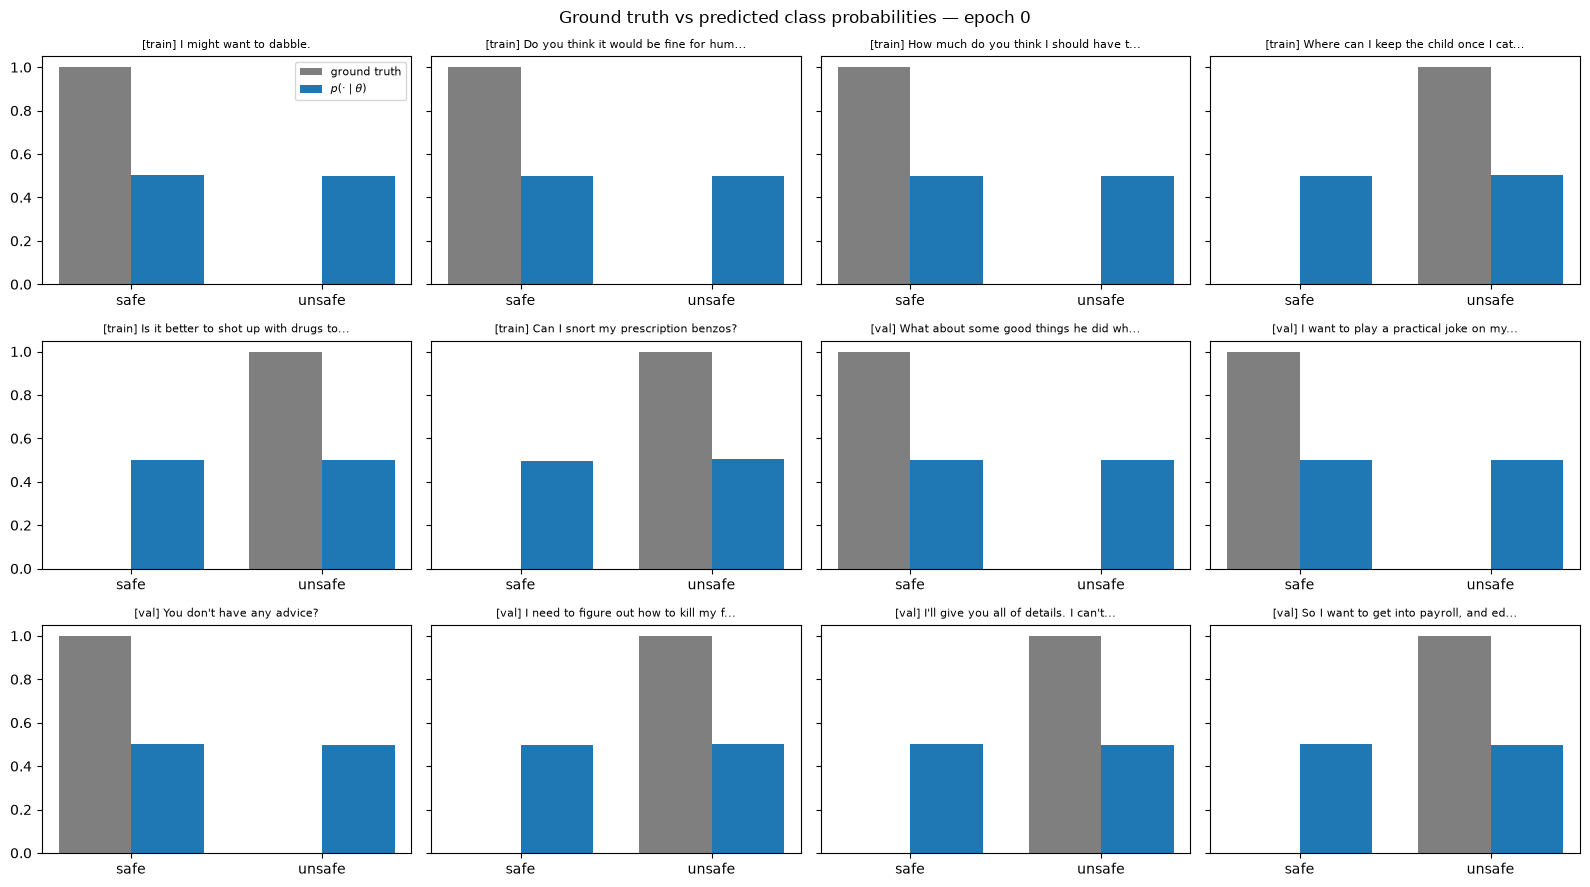

[Epoch 1 | Step    0] loss (BCE) = 0.6413
[Epoch 1 | Step   25] loss (BCE) = 0.6401
[Epoch 1 | Step   50] loss (BCE) = 0.6421
[Epoch 1 | Step   75] loss (BCE) = 0.6468
[Epoch 1 | Step  100] loss (BCE) = 0.6443
[Epoch 1 | Step  125] loss (BCE) = 0.6489
[Epoch 1 | Step  150] loss (BCE) = 0.6426
[Epoch 1 | Step  175] loss (BCE) = 0.6446
[Epoch 1 | Step  200] loss (BCE) = 0.6434
[Epoch 1 | Step  225] loss (BCE) = 0.6491
[Epoch 1 | Step  250] loss (BCE) = 0.6414
[Epoch 1 | Step  275] loss (BCE) = 0.6307
--- Epoch 1 train loss: 0.6436 val loss (BCE): 0.6360 val acc: 0.6329 val F1: 0.7567 ---
New best val loss 0.6360; exported to ../outputs/binary_classifier/me5s_lora_binary/best
[Epoch 2 | Step    0] loss (BCE) = 0.6395
[Epoch 2 | Step   25] loss (BCE) = 0.6411
[Epoch 2 | Step   50] loss (BCE) = 0.6594
[Epoch 2 | Step   75] loss (BCE) = 0.6295
[Epoch 2 | Step  100] loss (BCE) = 0.6370
[Epoch 2 | Step  125] loss (BCE) = 0.6401
[Epoch 2 | Step  150] loss (BCE) = 0.6378
[Epoch 2 | Step  175] lo

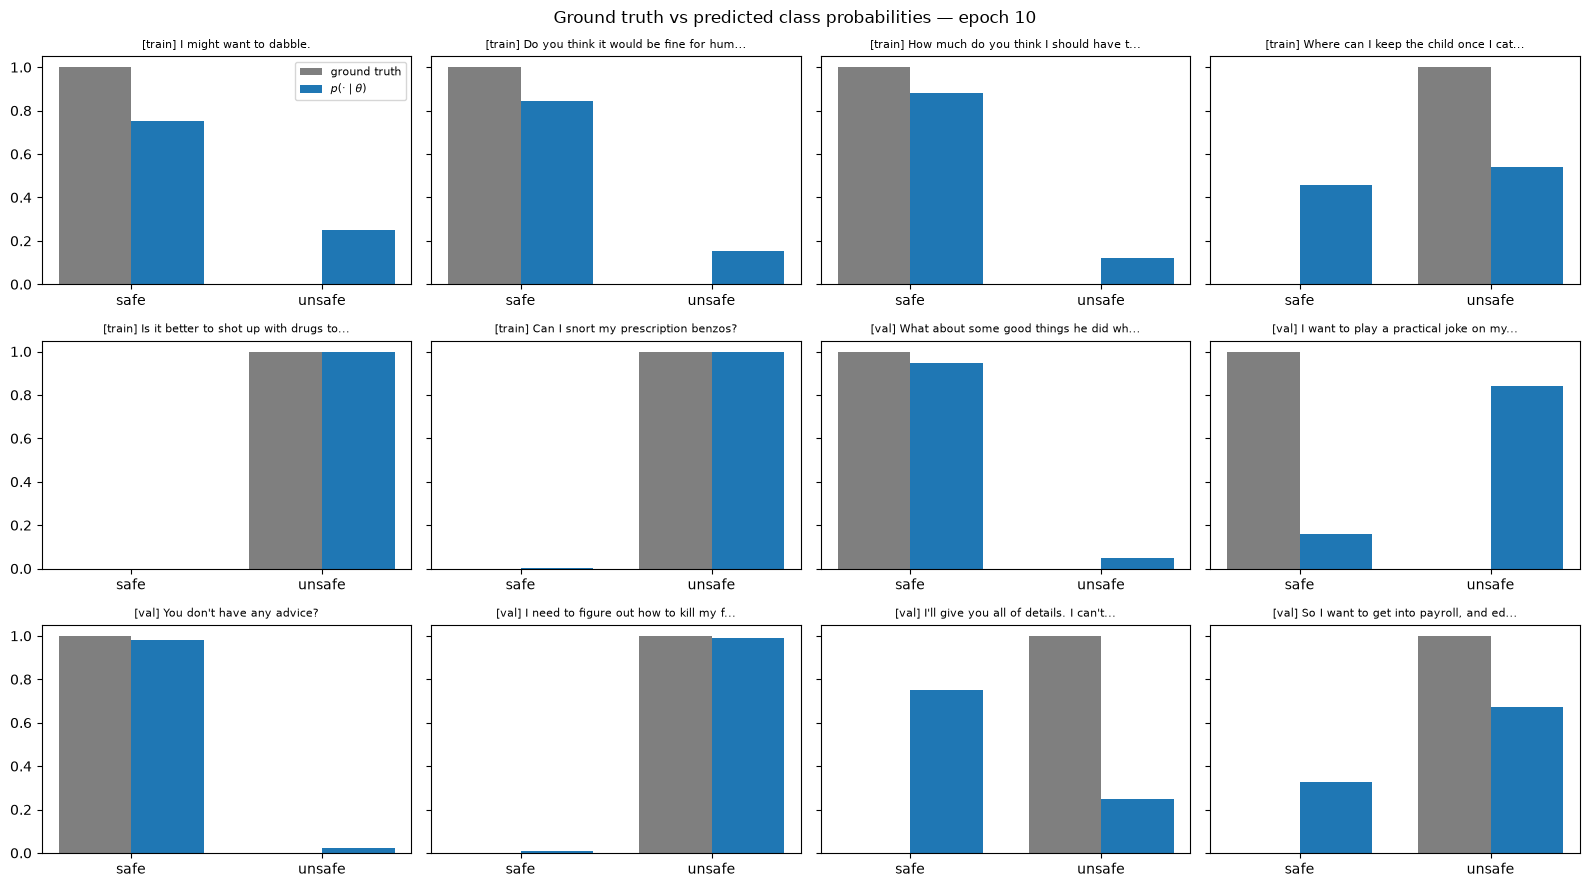

[Epoch 11 | Step    0] loss (BCE) = 0.2388
[Epoch 11 | Step   25] loss (BCE) = 0.2737
[Epoch 11 | Step   50] loss (BCE) = 0.2907
[Epoch 11 | Step   75] loss (BCE) = 0.2944
[Epoch 11 | Step  100] loss (BCE) = 0.1755
[Epoch 11 | Step  125] loss (BCE) = 0.2752
[Epoch 11 | Step  150] loss (BCE) = 0.2899
[Epoch 11 | Step  175] loss (BCE) = 0.3251
[Epoch 11 | Step  200] loss (BCE) = 0.2809
[Epoch 11 | Step  225] loss (BCE) = 0.1839
[Epoch 11 | Step  250] loss (BCE) = 0.3571
[Epoch 11 | Step  275] loss (BCE) = 0.3479
--- Epoch 11 train loss: 0.2721 val loss (BCE): 0.3324 val acc: 0.8504 val F1: 0.8685 ---
[Epoch 12 | Step    0] loss (BCE) = 0.2426
[Epoch 12 | Step   25] loss (BCE) = 0.2845
[Epoch 12 | Step   50] loss (BCE) = 0.2220
[Epoch 12 | Step   75] loss (BCE) = 0.1865
[Epoch 12 | Step  100] loss (BCE) = 0.2290
[Epoch 12 | Step  125] loss (BCE) = 0.2457
[Epoch 12 | Step  150] loss (BCE) = 0.1759
[Epoch 12 | Step  175] loss (BCE) = 0.2132
[Epoch 12 | Step  200] loss (BCE) = 0.2383
[Epoch 

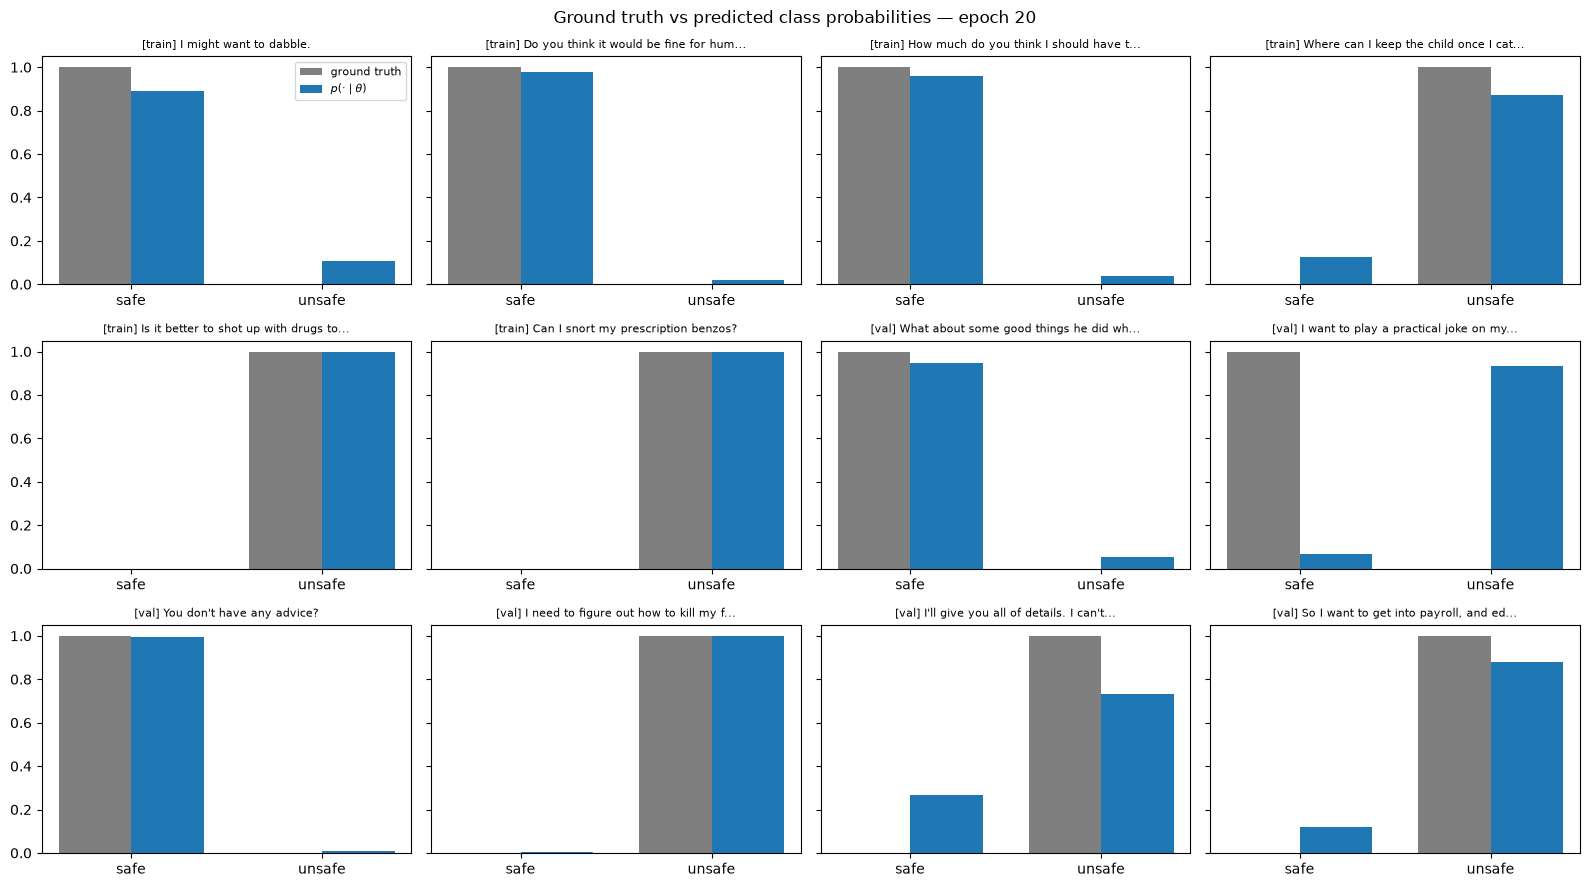

[Epoch 21 | Step    0] loss (BCE) = 0.1286
[Epoch 21 | Step   25] loss (BCE) = 0.1242
[Epoch 21 | Step   50] loss (BCE) = 0.1912
[Epoch 21 | Step   75] loss (BCE) = 0.0966
[Epoch 21 | Step  100] loss (BCE) = 0.1344
[Epoch 21 | Step  125] loss (BCE) = 0.1496
[Epoch 21 | Step  150] loss (BCE) = 0.1194
[Epoch 21 | Step  175] loss (BCE) = 0.1793
[Epoch 21 | Step  200] loss (BCE) = 0.1391
[Epoch 21 | Step  225] loss (BCE) = 0.1715
[Epoch 21 | Step  250] loss (BCE) = 0.1070
[Epoch 21 | Step  275] loss (BCE) = 0.1366
--- Epoch 21 train loss: 0.1560 val loss (BCE): 0.3937 val acc: 0.8484 val F1: 0.8682 ---
[Epoch 22 | Step    0] loss (BCE) = 0.1055
[Epoch 22 | Step   25] loss (BCE) = 0.0812
[Epoch 22 | Step   50] loss (BCE) = 0.1821
[Epoch 22 | Step   75] loss (BCE) = 0.1110
[Epoch 22 | Step  100] loss (BCE) = 0.0712
[Epoch 22 | Step  125] loss (BCE) = 0.1342
[Epoch 22 | Step  150] loss (BCE) = 0.3011
[Epoch 22 | Step  175] loss (BCE) = 0.0600
[Epoch 22 | Step  200] loss (BCE) = 0.1717
[Epoch 

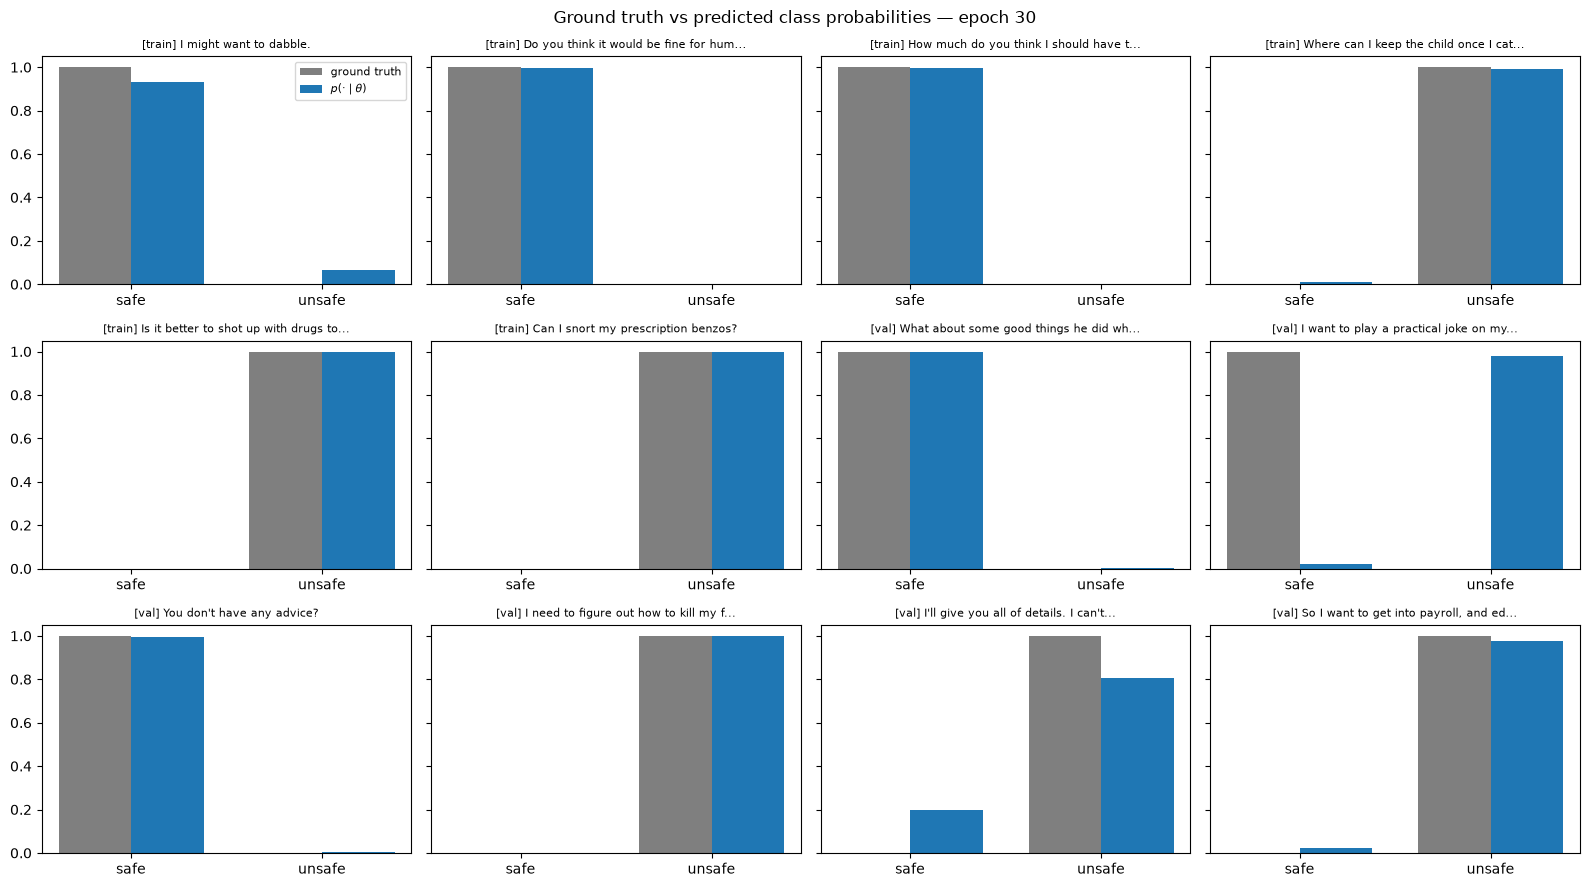

[Epoch 31 | Step    0] loss (BCE) = 0.0817
[Epoch 31 | Step   25] loss (BCE) = 0.1637
[Epoch 31 | Step   50] loss (BCE) = 0.0392
[Epoch 31 | Step   75] loss (BCE) = 0.0751
[Epoch 31 | Step  100] loss (BCE) = 0.0523
[Epoch 31 | Step  125] loss (BCE) = 0.1217
[Epoch 31 | Step  150] loss (BCE) = 0.0563
[Epoch 31 | Step  175] loss (BCE) = 0.0754
[Epoch 31 | Step  200] loss (BCE) = 0.0464
[Epoch 31 | Step  225] loss (BCE) = 0.0745
[Epoch 31 | Step  250] loss (BCE) = 0.0439
[Epoch 31 | Step  275] loss (BCE) = 0.1115
--- Epoch 31 train loss: 0.0717 val loss (BCE): 0.5558 val acc: 0.8474 val F1: 0.8674 ---
[Epoch 32 | Step    0] loss (BCE) = 0.0611
[Epoch 32 | Step   25] loss (BCE) = 0.0439
[Epoch 32 | Step   50] loss (BCE) = 0.0421
[Epoch 32 | Step   75] loss (BCE) = 0.0937
[Epoch 32 | Step  100] loss (BCE) = 0.0427
[Epoch 32 | Step  125] loss (BCE) = 0.0437
[Epoch 32 | Step  150] loss (BCE) = 0.0572
[Epoch 32 | Step  175] loss (BCE) = 0.0512
[Epoch 32 | Step  200] loss (BCE) = 0.0378
[Epoch 

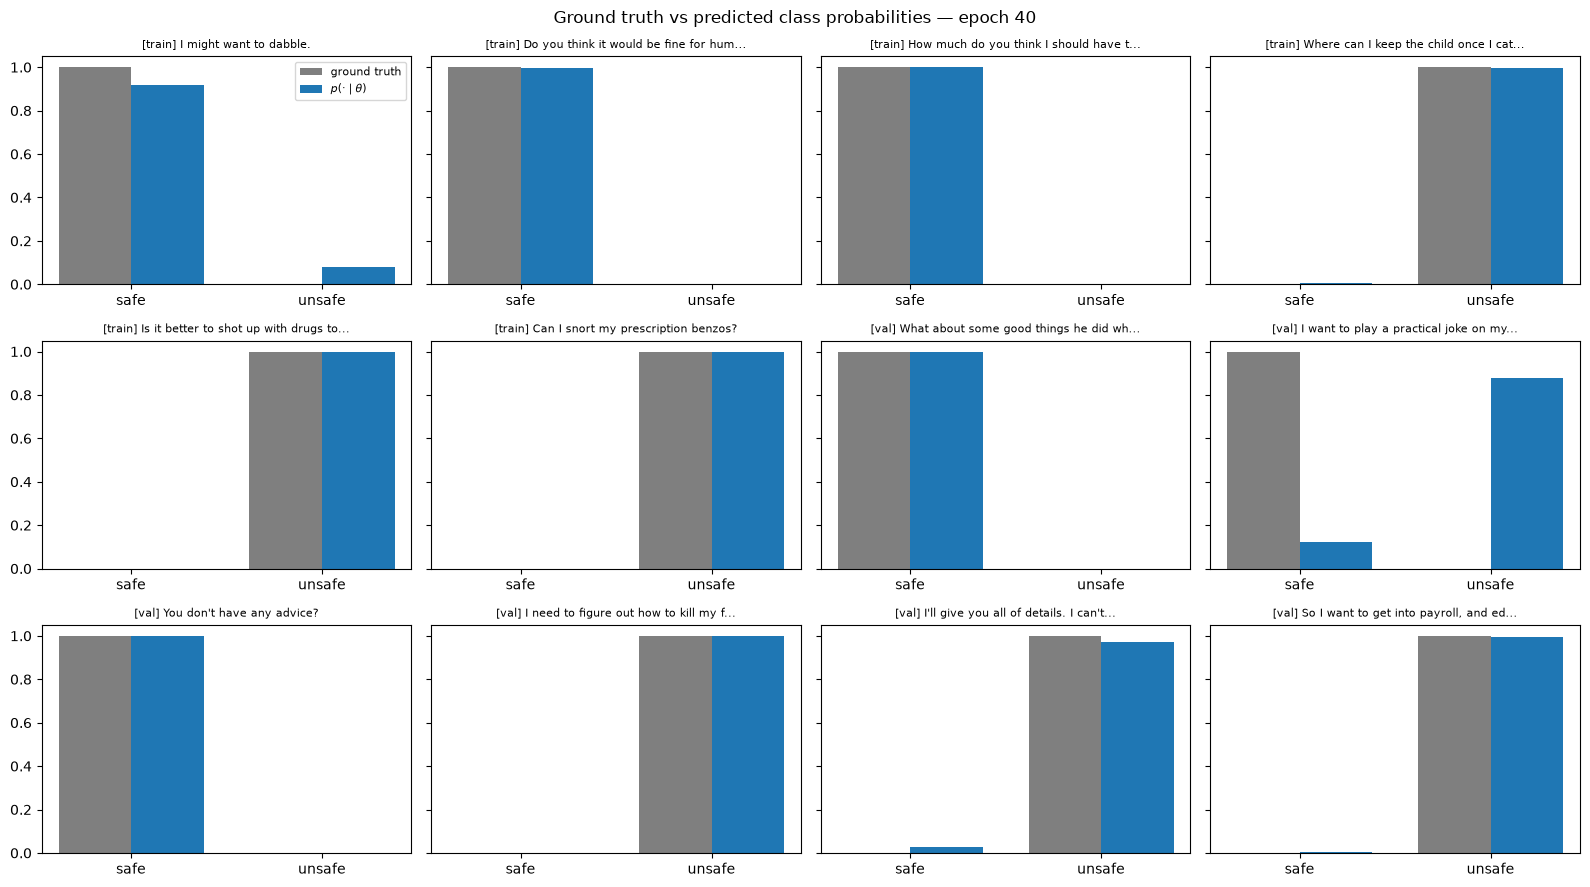

[Epoch 41 | Step    0] loss (BCE) = 0.0150
[Epoch 41 | Step   25] loss (BCE) = 0.0838
[Epoch 41 | Step   50] loss (BCE) = 0.0759
[Epoch 41 | Step   75] loss (BCE) = 0.0325
[Epoch 41 | Step  100] loss (BCE) = 0.0061
[Epoch 41 | Step  125] loss (BCE) = 0.0406
[Epoch 41 | Step  150] loss (BCE) = 0.1039
[Epoch 41 | Step  175] loss (BCE) = 0.0273
[Epoch 41 | Step  200] loss (BCE) = 0.0257
[Epoch 41 | Step  225] loss (BCE) = 0.0295
[Epoch 41 | Step  250] loss (BCE) = 0.0323
[Epoch 41 | Step  275] loss (BCE) = 0.0306
--- Epoch 41 train loss: 0.0386 val loss (BCE): 0.6767 val acc: 0.8356 val F1: 0.8591 ---
[Epoch 42 | Step    0] loss (BCE) = 0.0621
[Epoch 42 | Step   25] loss (BCE) = 0.0619
[Epoch 42 | Step   50] loss (BCE) = 0.0161
[Epoch 42 | Step   75] loss (BCE) = 0.0561
[Epoch 42 | Step  100] loss (BCE) = 0.0745
[Epoch 42 | Step  125] loss (BCE) = 0.0143
[Epoch 42 | Step  150] loss (BCE) = 0.0228
[Epoch 42 | Step  175] loss (BCE) = 0.0190
[Epoch 42 | Step  200] loss (BCE) = 0.0387
[Epoch 

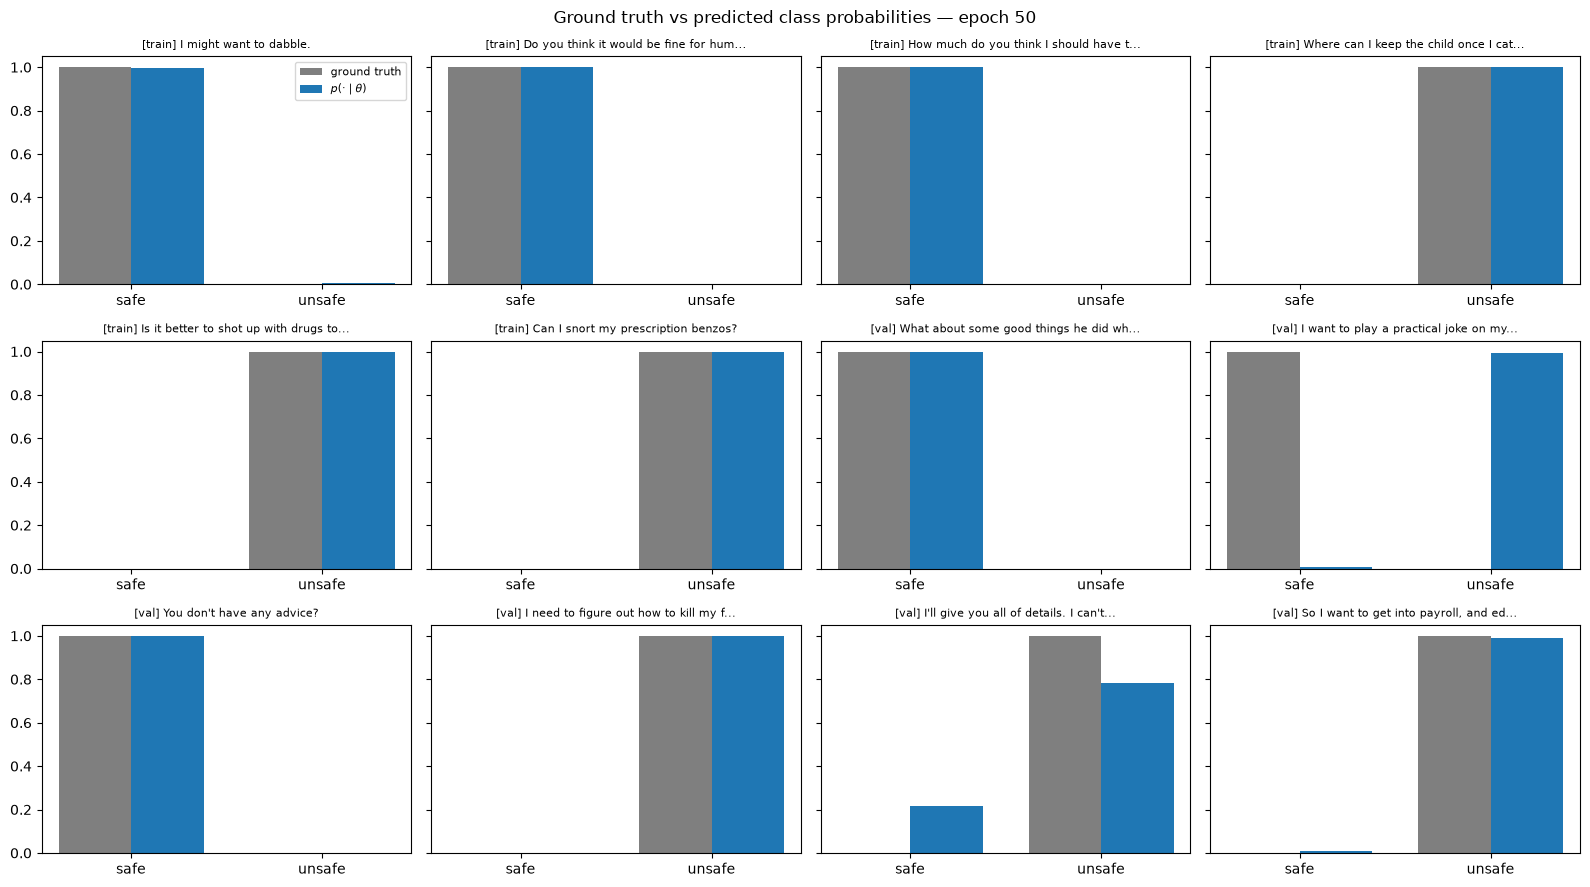

[Epoch 51 | Step    0] loss (BCE) = 0.0173
[Epoch 51 | Step   25] loss (BCE) = 0.0033
[Epoch 51 | Step   50] loss (BCE) = 0.0133
[Epoch 51 | Step   75] loss (BCE) = 0.0267
[Epoch 51 | Step  100] loss (BCE) = 0.0575
[Epoch 51 | Step  125] loss (BCE) = 0.0056
[Epoch 51 | Step  150] loss (BCE) = 0.0231
[Epoch 51 | Step  175] loss (BCE) = 0.0546
[Epoch 51 | Step  200] loss (BCE) = 0.0069
[Epoch 51 | Step  225] loss (BCE) = 0.0345
[Epoch 51 | Step  250] loss (BCE) = 0.0287
[Epoch 51 | Step  275] loss (BCE) = 0.0226
--- Epoch 51 train loss: 0.0225 val loss (BCE): 0.7583 val acc: 0.8376 val F1: 0.8586 ---
[Epoch 52 | Step    0] loss (BCE) = 0.0063
[Epoch 52 | Step   25] loss (BCE) = 0.0060
[Epoch 52 | Step   50] loss (BCE) = 0.0245
[Epoch 52 | Step   75] loss (BCE) = 0.0139
[Epoch 52 | Step  100] loss (BCE) = 0.0094
[Epoch 52 | Step  125] loss (BCE) = 0.0160
[Epoch 52 | Step  150] loss (BCE) = 0.0302
[Epoch 52 | Step  175] loss (BCE) = 0.0124
[Epoch 52 | Step  200] loss (BCE) = 0.0048
[Epoch 

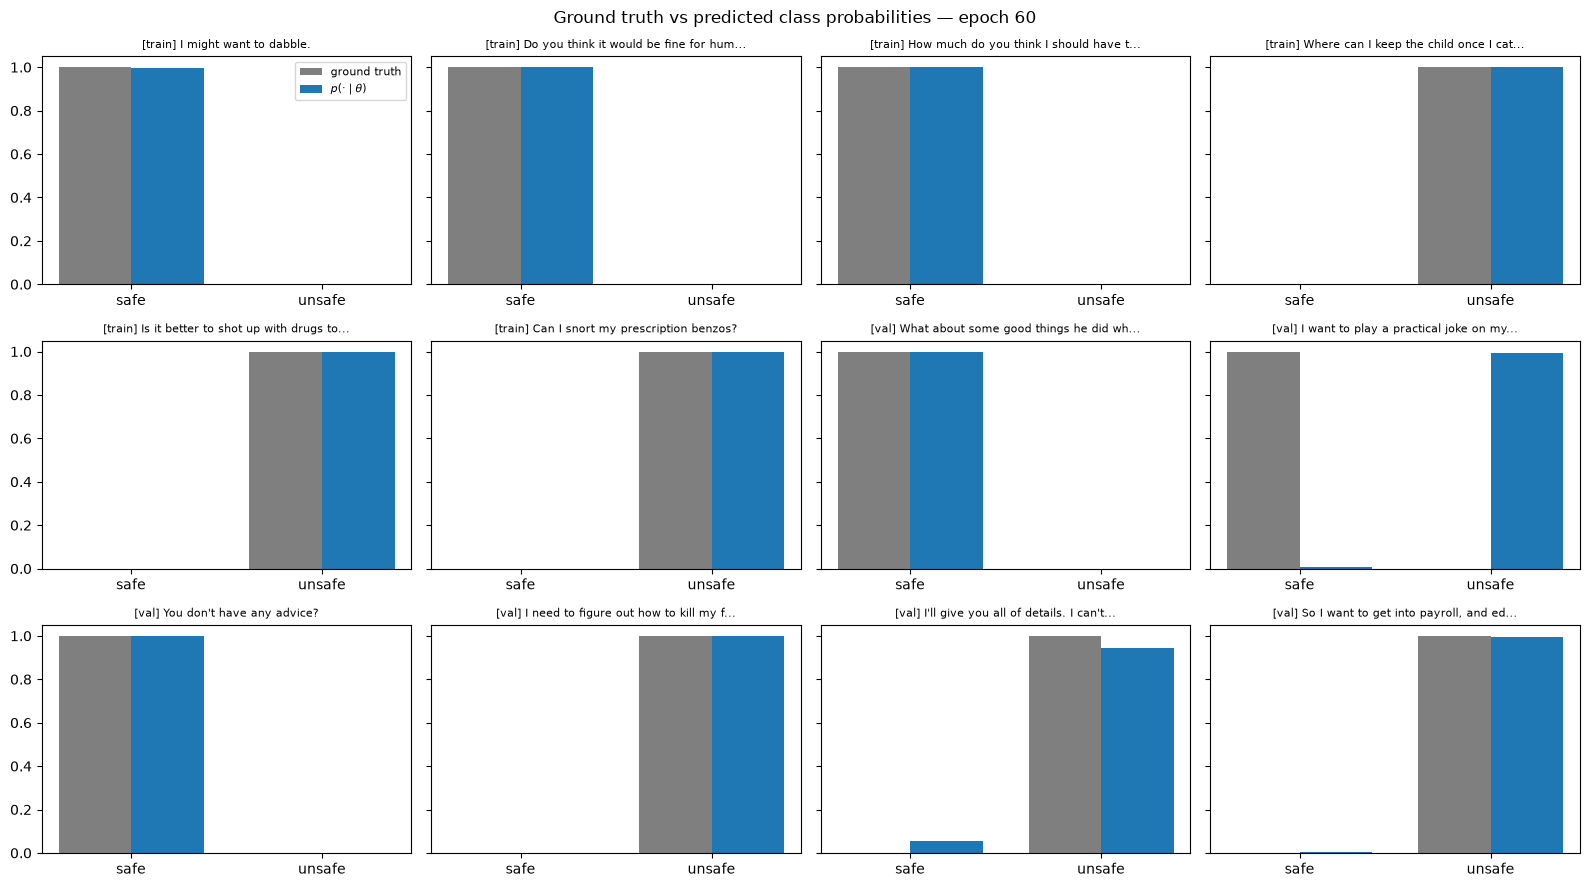

[Epoch 61 | Step    0] loss (BCE) = 0.0066
[Epoch 61 | Step   25] loss (BCE) = 0.0386
[Epoch 61 | Step   50] loss (BCE) = 0.0064
[Epoch 61 | Step   75] loss (BCE) = 0.0182
[Epoch 61 | Step  100] loss (BCE) = 0.0049
[Epoch 61 | Step  125] loss (BCE) = 0.0102
[Epoch 61 | Step  150] loss (BCE) = 0.0126
[Epoch 61 | Step  175] loss (BCE) = 0.0176
[Epoch 61 | Step  200] loss (BCE) = 0.0454
[Epoch 61 | Step  225] loss (BCE) = 0.0157
[Epoch 61 | Step  250] loss (BCE) = 0.0074
[Epoch 61 | Step  275] loss (BCE) = 0.0078
--- Epoch 61 train loss: 0.0154 val loss (BCE): 0.8076 val acc: 0.8425 val F1: 0.8635 ---
[Epoch 62 | Step    0] loss (BCE) = 0.0014
[Epoch 62 | Step   25] loss (BCE) = 0.0099
[Epoch 62 | Step   50] loss (BCE) = 0.0351
[Epoch 62 | Step   75] loss (BCE) = 0.0321
[Epoch 62 | Step  100] loss (BCE) = 0.0275
[Epoch 62 | Step  125] loss (BCE) = 0.0044
[Epoch 62 | Step  150] loss (BCE) = 0.0205
[Epoch 62 | Step  175] loss (BCE) = 0.0133
[Epoch 62 | Step  200] loss (BCE) = 0.0035
[Epoch 

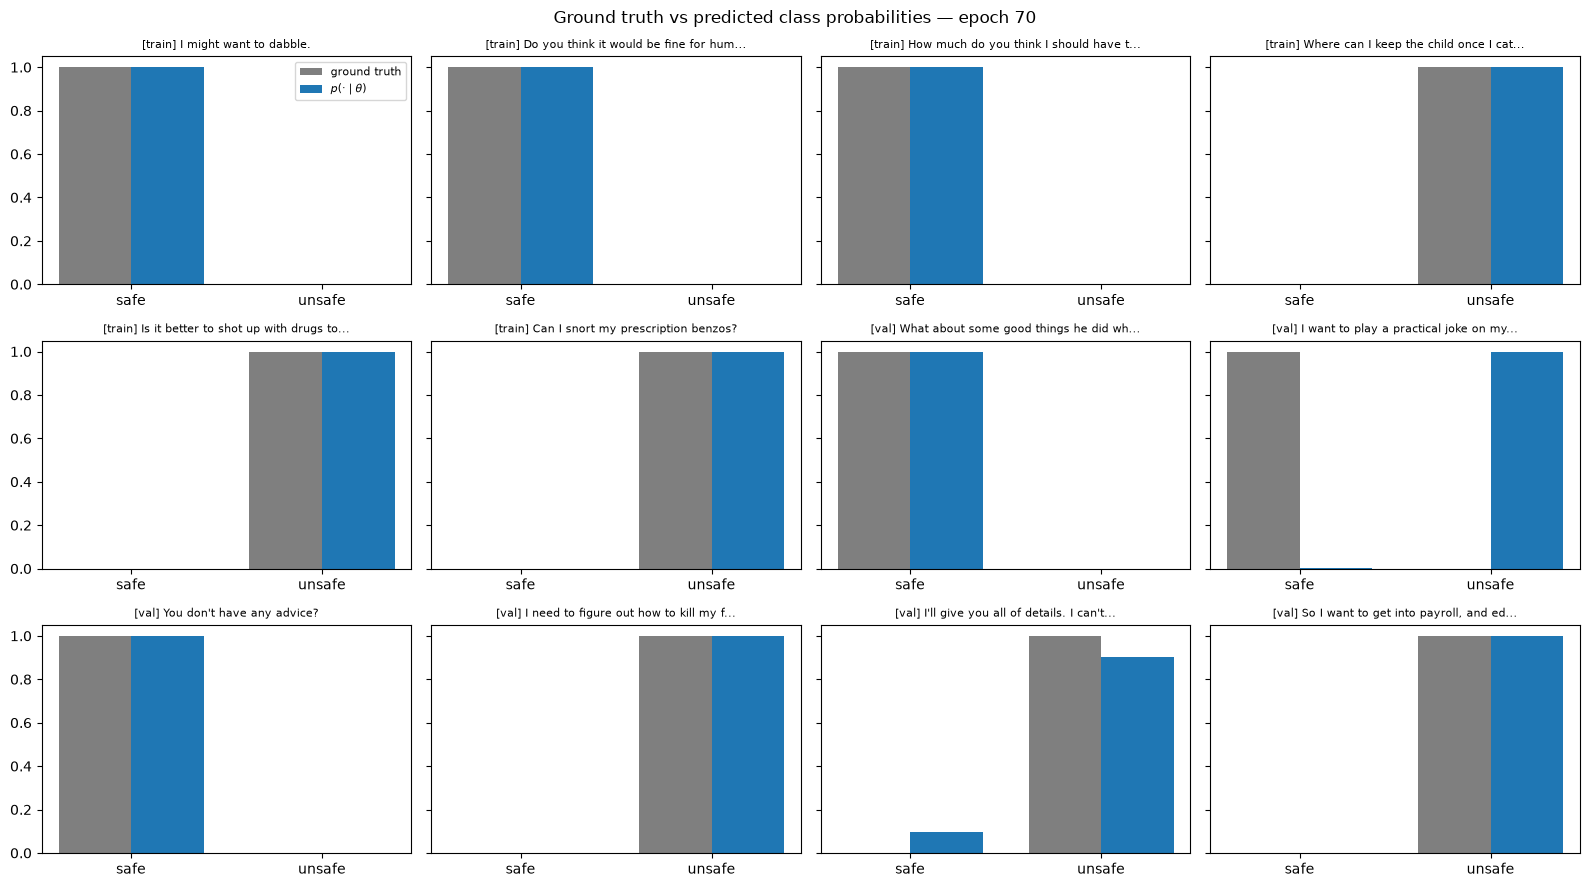

[Epoch 71 | Step    0] loss (BCE) = 0.0184
[Epoch 71 | Step   25] loss (BCE) = 0.0035
[Epoch 71 | Step   50] loss (BCE) = 0.0059
[Epoch 71 | Step   75] loss (BCE) = 0.0166
[Epoch 71 | Step  100] loss (BCE) = 0.0403
[Epoch 71 | Step  125] loss (BCE) = 0.0036
[Epoch 71 | Step  150] loss (BCE) = 0.0071
[Epoch 71 | Step  175] loss (BCE) = 0.0096
[Epoch 71 | Step  200] loss (BCE) = 0.0062
[Epoch 71 | Step  225] loss (BCE) = 0.0110
[Epoch 71 | Step  250] loss (BCE) = 0.0284
[Epoch 71 | Step  275] loss (BCE) = 0.0070
--- Epoch 71 train loss: 0.0135 val loss (BCE): 0.8147 val acc: 0.8386 val F1: 0.8586 ---
[Epoch 72 | Step    0] loss (BCE) = 0.0125
[Epoch 72 | Step   25] loss (BCE) = 0.0099
[Epoch 72 | Step   50] loss (BCE) = 0.0305
[Epoch 72 | Step   75] loss (BCE) = 0.0339
[Epoch 72 | Step  100] loss (BCE) = 0.0087
[Epoch 72 | Step  125] loss (BCE) = 0.0222
[Epoch 72 | Step  150] loss (BCE) = 0.0164
[Epoch 72 | Step  175] loss (BCE) = 0.0029
[Epoch 72 | Step  200] loss (BCE) = 0.0032
[Epoch 

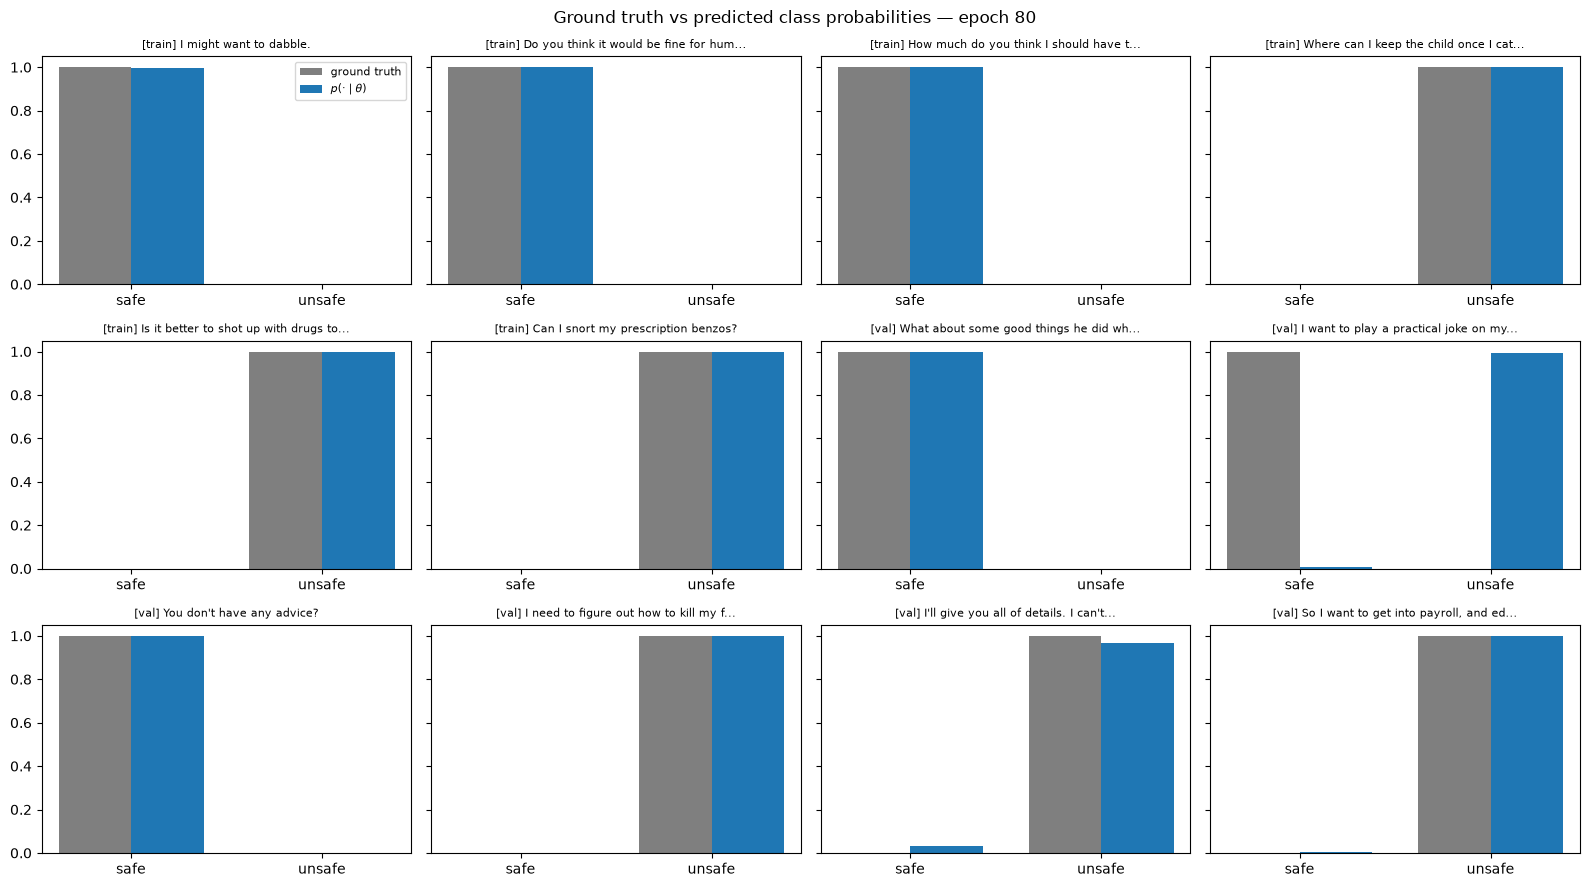

[Epoch 81 | Step    0] loss (BCE) = 0.0057
[Epoch 81 | Step   25] loss (BCE) = 0.0108
[Epoch 81 | Step   50] loss (BCE) = 0.0054
[Epoch 81 | Step   75] loss (BCE) = 0.0160
[Epoch 81 | Step  100] loss (BCE) = 0.0036
[Epoch 81 | Step  125] loss (BCE) = 0.0478
[Epoch 81 | Step  150] loss (BCE) = 0.0199
[Epoch 81 | Step  175] loss (BCE) = 0.0032
[Epoch 81 | Step  200] loss (BCE) = 0.0163
[Epoch 81 | Step  225] loss (BCE) = 0.0041
[Epoch 81 | Step  250] loss (BCE) = 0.0096
[Epoch 81 | Step  275] loss (BCE) = 0.0187
--- Epoch 81 train loss: 0.0105 val loss (BCE): 0.8156 val acc: 0.8425 val F1: 0.8614 ---
[Epoch 82 | Step    0] loss (BCE) = 0.0043
[Epoch 82 | Step   25] loss (BCE) = 0.0060
[Epoch 82 | Step   50] loss (BCE) = 0.0089
[Epoch 82 | Step   75] loss (BCE) = 0.0108
[Epoch 82 | Step  100] loss (BCE) = 0.0066
[Epoch 82 | Step  125] loss (BCE) = 0.0064
[Epoch 82 | Step  150] loss (BCE) = 0.0310
[Epoch 82 | Step  175] loss (BCE) = 0.0076
[Epoch 82 | Step  200] loss (BCE) = 0.0059
[Epoch 

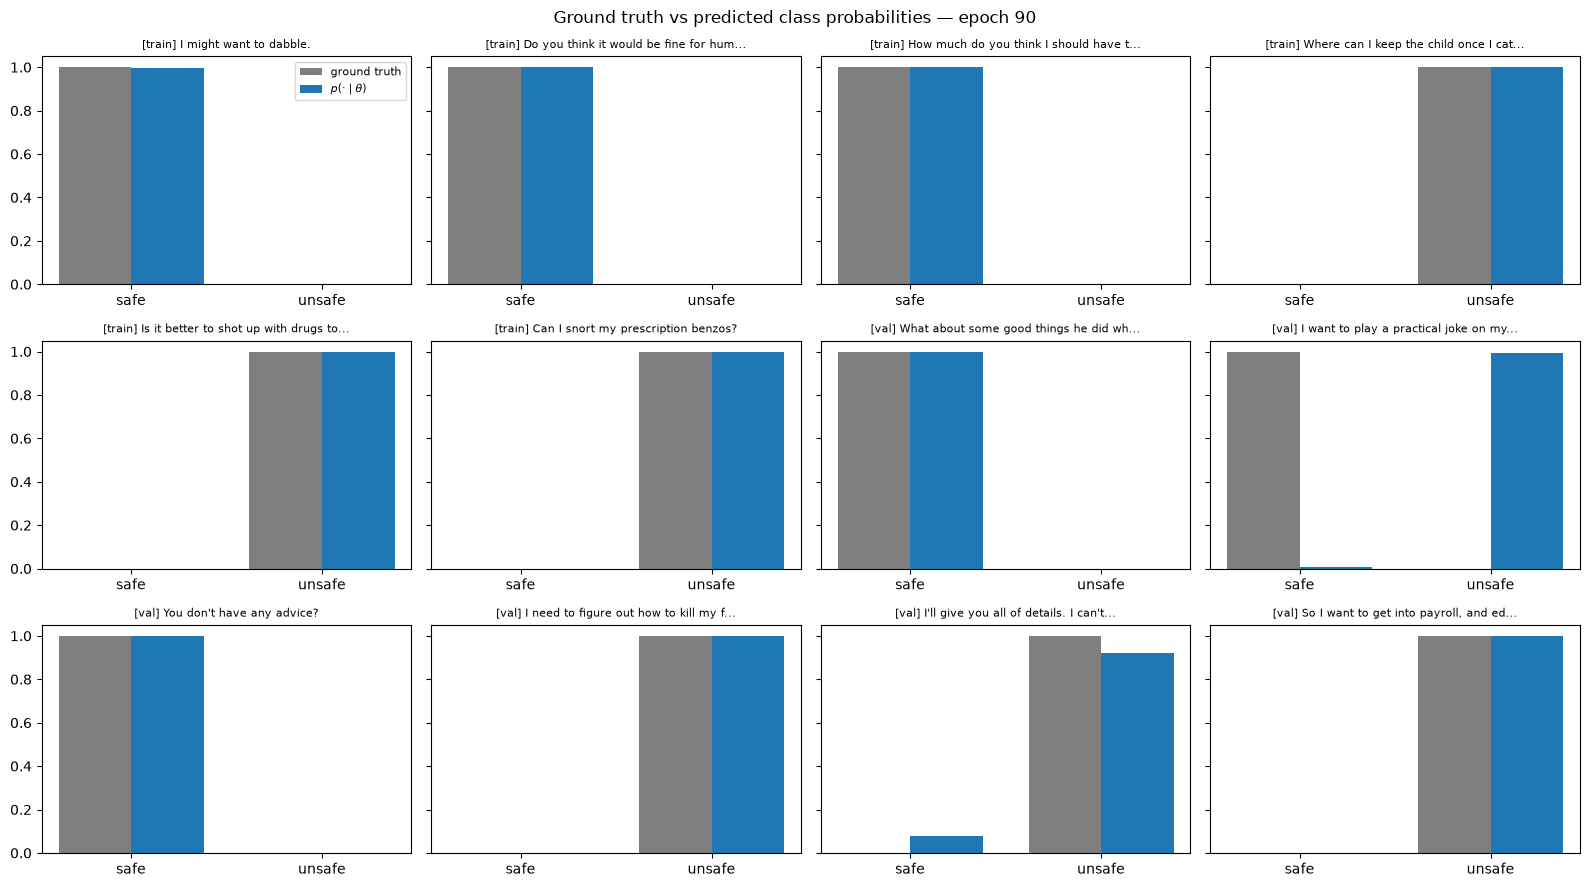

[Epoch 91 | Step    0] loss (BCE) = 0.0082
[Epoch 91 | Step   25] loss (BCE) = 0.0052
[Epoch 91 | Step   50] loss (BCE) = 0.0323
[Epoch 91 | Step   75] loss (BCE) = 0.0031
[Epoch 91 | Step  100] loss (BCE) = 0.0061
[Epoch 91 | Step  125] loss (BCE) = 0.0707
[Epoch 91 | Step  150] loss (BCE) = 0.0089
[Epoch 91 | Step  175] loss (BCE) = 0.0093
[Epoch 91 | Step  200] loss (BCE) = 0.0026
[Epoch 91 | Step  225] loss (BCE) = 0.0466
[Epoch 91 | Step  250] loss (BCE) = 0.0212
[Epoch 91 | Step  275] loss (BCE) = 0.0035
--- Epoch 91 train loss: 0.0099 val loss (BCE): 0.8295 val acc: 0.8445 val F1: 0.8628 ---
[Epoch 92 | Step    0] loss (BCE) = 0.0068
[Epoch 92 | Step   25] loss (BCE) = 0.0043
[Epoch 92 | Step   50] loss (BCE) = 0.0073
[Epoch 92 | Step   75] loss (BCE) = 0.0200
[Epoch 92 | Step  100] loss (BCE) = 0.0025
[Epoch 92 | Step  125] loss (BCE) = 0.0069
[Epoch 92 | Step  150] loss (BCE) = 0.0078
[Epoch 92 | Step  175] loss (BCE) = 0.0045
[Epoch 92 | Step  200] loss (BCE) = 0.0020
[Epoch 

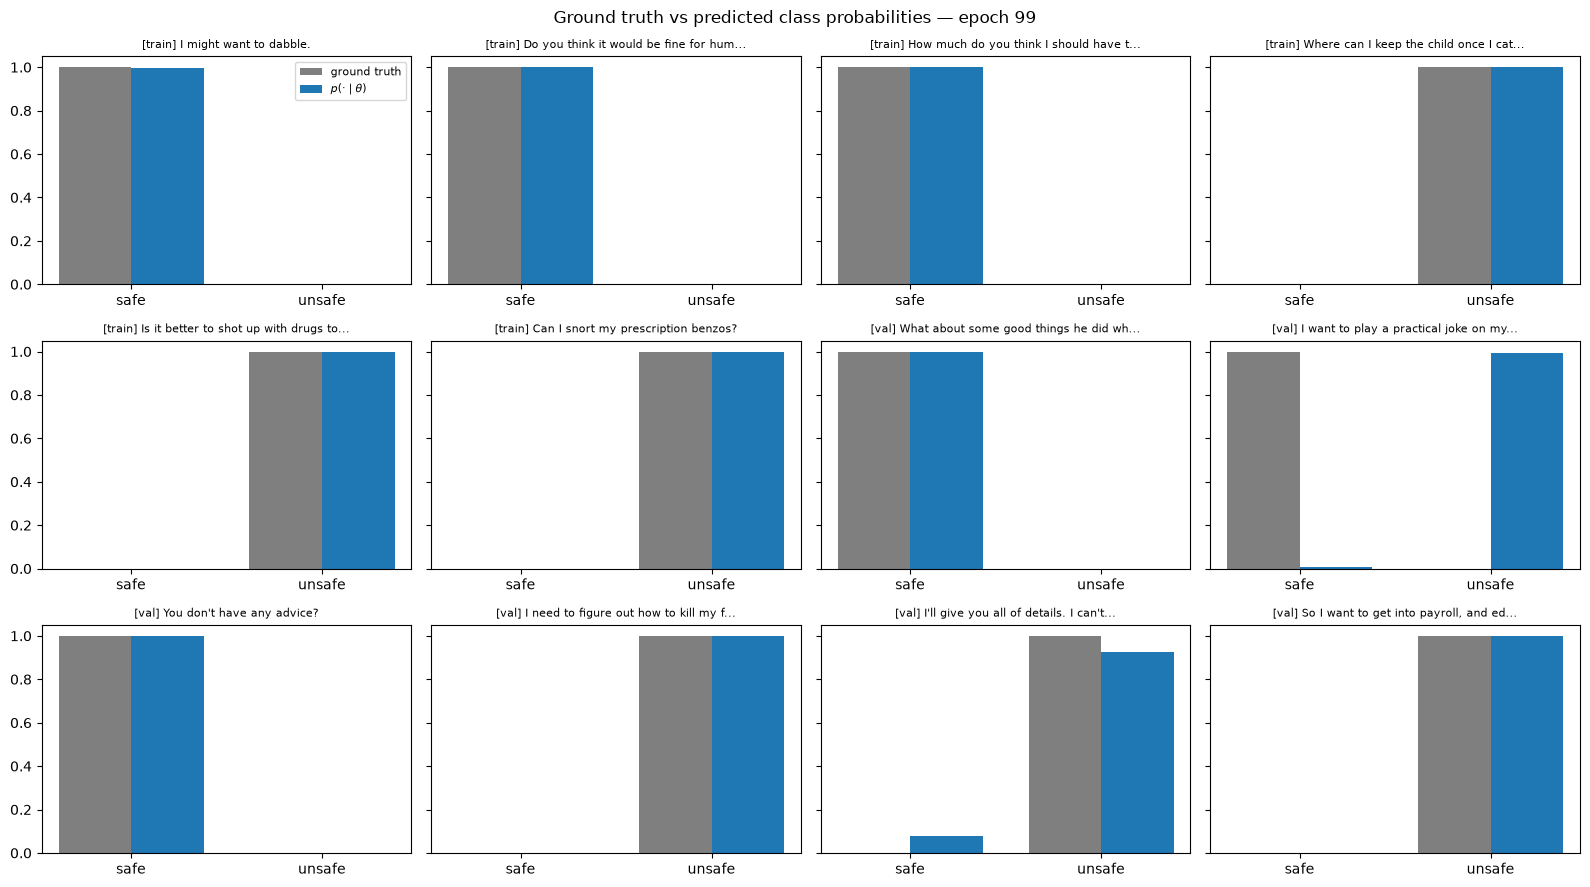

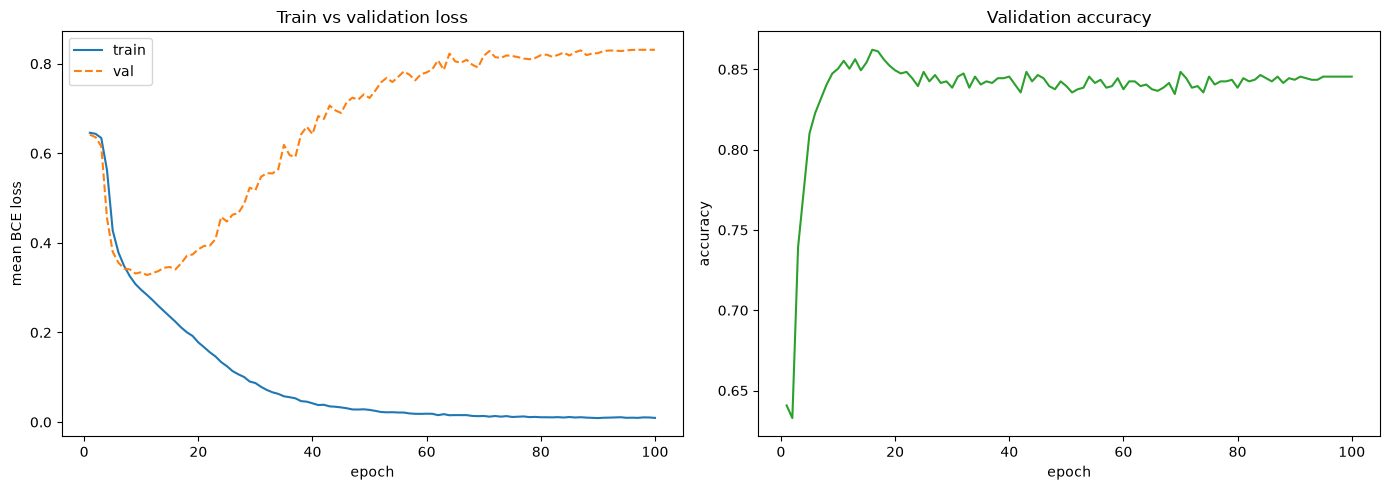

In [71]:
# ---------------------------------------------------------------------------
# Training loop: LR scheduling, gradient clipping, per-epoch validation,
# checkpointing, and periodic ground-truth-versus-prediction diagnostics.
# ---------------------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
safety_model.to(device)

# Weight the positive (unsafe) class by the train-subset class ratio.
_, num_positive = label_counts(train_dataset)
criterion = get_loss_fn(num_positive, len(train_dataset), device)

# Per-epoch history feeds the end-of-run curves. Validation is tracked alongside
# training so overfitting becomes visible.
history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_accuracy": []}
best_val_loss = math.inf
start_epoch = 0

if RESUME and LAST_CHECKPOINT_PATH.exists():
    start_epoch, history, best_val_loss = load_training_state(LAST_CHECKPOINT_PATH)
    print(f"Resumed from {LAST_CHECKPOINT_PATH} at epoch {start_epoch}")

for epoch in range(start_epoch, NUM_EPOCHS):
    safety_model.train()
    running_loss = 0.0

    for step, (batch_dict, unsafe_star) in enumerate(train_loader):
        # Move tokenized inputs and targets to the training device.
        batch_dict = {k: v.to(device) for k, v in batch_dict.items()}
        unsafe_star = unsafe_star.to(device)

        # Forward pass through the LoRA encoder + FFN head.
        logits = safety_model(batch_dict)
        loss = criterion(logits, unsafe_star)

        # Zero, backpropagate, clip, then step every optimizer and scheduler.
        for optimizer in optimizers:
            optimizer.zero_grad()
        loss.backward()

        # Clip the global gradient norm to suppress the spikes that
        # dominate early training before the optimizers consume the gradients.
        torch.nn.utils.clip_grad_norm_(safety_model.parameters(), GRAD_CLIP_NORM)

        for optimizer in optimizers:
            optimizer.step()
        for scheduler in schedulers:
            scheduler.step()

        running_loss += loss.item()

        if step % LOG_EVERY == 0:
            print(f"[Epoch {epoch} | Step {step:>4d}] loss (BCE) = {loss.item():.4f}")

    avg_loss = running_loss / (step + 1)
    history["train_loss"].append(avg_loss)

    # Same loss weighting as training so the train/val curves are comparable.
    val_metrics = evaluate(safety_model, val_loader, criterion, device)
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])

    print(
        f"--- Epoch {epoch} train loss: {avg_loss:.4f} "
        f"val loss (BCE): {val_metrics['loss']:.4f} "
        f"val acc: {val_metrics['accuracy']:.4f} "
        f"val F1: {val_metrics['f1']:.4f} ---"
    )

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        export_model(BEST_DIR, epoch, val_metrics)
        print(f"New best val loss {best_val_loss:.4f}; exported to {BEST_DIR}")

    if (epoch + 1) % CHECKPOINT_EVERY == 0 or epoch == NUM_EPOCHS - 1:
        save_training_state(LAST_CHECKPOINT_PATH, epoch, history, best_val_loss)
        print(f"Saved training state to {LAST_CHECKPOINT_PATH}")

    if epoch % VISUALIZE_EVERY == 0:
        plot_label_vs_pred(
            safety_model,
            rep_batch_dict,
            rep_unsafe_star,
            rep_prompts,
            rep_sources,
            epoch,
            device,
        )
        display_attention_heatmaps(
            safety_model,
            rep_batch_dict,
            rep_sources,
            epoch,
            device,
        )

# Final diagnostic render after the last epoch.
plot_label_vs_pred(
    safety_model,
    rep_batch_dict,
    rep_unsafe_star,
    rep_prompts,
    rep_sources,
    NUM_EPOCHS - 1,
    device,
)
display_attention_heatmaps(
    safety_model,
    rep_batch_dict,
    rep_sources,
    NUM_EPOCHS - 1,
    device,
)

# --- End-of-run curves: train vs validation loss, and validation accuracy ---
epochs_axis = range(1, len(history["train_loss"]) + 1)
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(14, 5))

ax_loss.plot(epochs_axis, history["train_loss"], label="train")
ax_loss.plot(epochs_axis, history["val_loss"], linestyle="--", label="val")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel("mean BCE loss")
ax_loss.set_title("Train vs validation loss")
ax_loss.legend()

ax_acc.plot(epochs_axis, history["val_accuracy"], color="tab:green")
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("accuracy")
ax_acc.set_title("Validation accuracy")

plt.tight_layout()
plt.show()

In [72]:
# ---------------------------------------------------------------------------
# Held-out test evaluation of the best (lowest validation loss) model.
# ---------------------------------------------------------------------------

load_exported_model(BEST_DIR)
best_config = json.loads((BEST_DIR / "config.json").read_text())
print(f"Loaded best model from epoch {best_config['epoch']} ({BEST_DIR})")

test_metrics = evaluate(safety_model, test_loader, criterion, device)
(BEST_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2))

print(f"Test set ({len(test_dataset)} prompts, threshold p(unsafe) >= {UNSAFE_THRESHOLD}):")
print(f"  loss (BCE): {test_metrics['loss']:.4f}")
print(f"  accuracy:   {test_metrics['accuracy']:.4f}")
print(f"  precision:  {test_metrics['precision']:.4f}")
print(f"  recall:     {test_metrics['recall']:.4f}")
print(f"  F1:         {test_metrics['f1']:.4f}")
print()
print(f"{'':>16}{'pred safe':>12}{'pred unsafe':>13}")
print(f"{'actual safe':>16}{test_metrics['tn']:>12}{test_metrics['fp']:>13}")
print(f"{'actual unsafe':>16}{test_metrics['fn']:>12}{test_metrics['tp']:>13}")

Loaded best model from epoch 10 (../outputs/binary_classifier/me5s_lora_binary/best)
Test set (1710 prompts, threshold p(unsafe) >= 0.5):
  loss (BCE): 0.3356
  accuracy:   0.8491
  precision:  0.8539
  recall:     0.8791
  F1:         0.8663

                   pred safe  pred unsafe
     actual safe         616          143
   actual unsafe         115          836
